# **PROJECT TITLE:  EMPLOYEE PERFORMANCE ANALYSIS**
### **presented by kolum Kipkoech cosmas**

1. **Executive Summary**

INX Future Inc. (INX) has historically maintained a prestigious reputation as a "Top 20 Best Employer." However, recent declines in performance indexes and an 8% drop in client satisfaction necessitated a data-driven intervention. This project utilizes machine learning to uncover the underlying causes of performance issues.
The analysis identified that performance is largely driven by Environment Satisfaction, Salary Hike Percent, and Promotion History. Among five models tested, the Gradient Boosting Classifier emerged as the champion model with an accuracy of 91%. These findings allow management to take surgical actions to improve performance without broadly damaging employee morale.

2. **Introduction**

2.1**Background**

INX Future Inc. is a leading global data analytics and automation solutions provider with a 15-year business presence. Despite its employee-friendly culture, the company recently faced service delivery escalations.

2.2 **Problem Statement**

Management is currently in a "morale dilemma." Penalizing non-performers could damage the company's market perception as a top employer, yet inaction continues to harm client satisfaction. Mr. Brain (CEO) requires objective indicators to identify non-performing employees and the root causes behind their decline.

**2.3 Project Objectives**

Based on the requirements set by management, the project focuses on achieving the following four insights:

1.	**Department-wise Performance Analysis:** To identify performance variations and trends across different business units.
2.	**Identification of Top 3 Factors:** To pinpoint the most significant variables affecting employee performance ratings.
3.	**Predictive Modeling for Recruitment:** To build and train a machine learning model that predicts performance based on input factors, intended for use in the hiring process.
4.	**Strategic Recommendations:** To provide data-driven solutions for improving overall employee performance based on analytical insights.

**3. Methodology**

3.1 **Data Collection**

The dataset consisted of 1,200 employee records with 28 features, encompassing demographics, psychological factors, and job-related metrics.

3.2 **Tools for Analysis**

•	Tool: Python programming

•	Data Manipulation: Pandas, NumPy

•	Visualization: Matplotlib, Seaborn

•	Machine Learning: Scikit-learn (Ensemble methods, SVM, KNN)

3.3 **Data Preprocessing & EDA**

•	Initial Assessment: The data was verified to be clean, with no missing values or duplicate entries.

•	Exploratory Data Analysis (EDA): Visualized distributions of age, tenure, and performance ratings.

•	Outliers Removal: Managed using the Interquartile Range (IQR) method on numerical columns to ensure model reliability.

**3.4 Dimensionality Reduction: Principal Component Analysis (PCA)**

In this project, PCA was implemented to handle the high dimensionality of the dataset (43 features after encoding). Reasons for using PCA:

•	Reducing Complexity: PCA transforms a large set of variables into a smaller one that still contains most of the information, making the model more efficient.

•	Preventing Overfitting: By reducing noise and redundant features, PCA helps the model generalize better to new data.

•	Multicollinearity Mitigation: It addresses issues where features are highly correlated with each other, which can confuse certain algorithms.

•	Enhanced Visualization: It allows complex, multi-dimensional data to be compressed into 2D or 3D for better pattern recognition.

**3.5 Feature Engineering**

•	**Label Encoder:** Applied to ordinal features (e.g. perfomance rating).

•	**One Hot Encoder:** Applied to nominal categorical variables (e.g., Department, Education Background) to avoid mathematical bias.

4.**Performance Insights & Results**

**4.1 Department-wise Performances**

Analysis shows that performance is not uniform across units:

•	Development and Data Science show the highest average performance ratings.

•	Sales demonstrates the highest variance, suggesting localized challenges in motivation or environment within that unit.

**4.2 Top 5 Factors Affecting Employee Performance**

Based on the feature importance analysis within the **Gradient Boosting model,** the following five factors were identified as the primary drivers of performance:

1.	**EmpLastSalaryHikePercent (26.4%):** This is the most influential feature. High salary increment percentages strongly correlate with top-tier performance prediction.

2.	**EmpEnvironmentSatisfaction (22.8%):** Work environment satisfaction is the second strongest predictor, highlighting the importance of workplace culture.

3.	**YearsSinceLastPromotion (19.0%):** Time since the last promotion significantly affects outcomes; long gaps act as a major performance inhibitor.

4.	**ExperienceYearsAtThisCompany (5.2%):** Deep organizational knowledge and tenure contribute moderately to higher efficiency and output.

5.	**EmpJobRole_Developer (4.5%):** Being in the Developer job role has a measurable and specific predictive influence on high-performance ratings.

**4.3 Model Comparison and Selection**

To identify the most accurate predictor, five different machine learning models were trained and evaluated. The Gradient Boosting Classifier outperformed all other models across key metrics.


**No.	          Model	         Accuracy**

1.		Gradient Boosting	91%

2.		Random Forest	89%
3.		Support Vector Machine classifier (Linear)	81%
4.		Logistic Regression	77%
5.		KNN	74%

**4.4 Predictive Model for Hiring**

The **Gradient Boosting Classifier** was selected as the champion model. It serves as a predictive tool to screen candidates during the hiring process.

•	Accuracy: 91%

•	Capability: It predicts performance ratings (2, 3, and 4) based on 43 derived factors, allowing HR to hire individuals with high-performance potential.

**5. Strategic Recommendations**

To improve employee performance at INX, the following actions are recommended:

1.	**Optimization of Salary Increment Structures:** As the most influential feature, the company must ensure salary hikes are competitive and transparently linked to performance. High-increment percentages are the strongest predictors of top-tier performance levels.

2.	**Target Environmental Satisfaction:** Implement engagement programs to improve the workplace culture and physical environment.

3.	**Transparent Reward Systems:** Re-align salary hike structures to ensure they clearly reward high performance, addressing the #1 motivator.

4.	**Modernize Recruitment:** Deploy the Gradient Boosting model in the hiring pipeline to objectively select candidates who statistically align with high-performance traits.

5.	**Clear Career Pathing:** Establish transparent promotion cycles to reduce stagnation and maintain long-term performance.

6.	**Targeted Support for Technical Roles:** Being in a Developer job role has a measurable influence on performance ratings. Specific resource allocation and specialized training for these roles will further maximize their predictive performance potential.

6. **Conclusion**

The analysis concludes that performance at INX is a product of environmental factors and growth opportunities. By focusing on the top 5 features that provide 80% of the predictive power, management can efficiently restore client satisfaction while maintaining the company's status as a premier employer. Using the **Gradient Boosting model** ensures that performance evaluations and hiring decisions are rooted in objective data rather than subjective bias.



# Import Libraries for analysis

In [101]:
#import libraries for analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.calibration import LabelEncoder
from  sklearn.model_selection import train_test_split, GridSearchCV,cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC


###**loading dataset**

In [102]:
data = pd.read_csv('C:\\Users\\user\\Downloads\\INX_Future.csv')
data.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


After uploading, the files will be available in the current working directory of your Colab notebook (e.g., `/content/`). You can then load them using pandas as you tried to do before.

In [103]:
#check the data informations
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

there are two data types: Interger and Object

In [104]:
#checking the null calues
data.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

there are no null values in the dataset

In [105]:
#checking the duplicates in the dataset
data.duplicated().sum()

np.int64(0)

there is no duplicates in the datasets

In [106]:
# decribtions of the data
data.describe()

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating
count,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,2.89250,2.715833,65.981667,2.731667,2.067500,2.732500,2.665000,15.222500,2.725000,11.330000,2.785833,2.744167,7.077500,4.291667,2.194167,4.105000,2.948333
std,9.087289,8.176636,1.04412,1.090599,20.211302,0.707164,1.107836,1.100888,2.469384,3.625918,1.075642,7.797228,1.263446,0.699374,6.236899,3.613744,3.221560,3.541576,0.518866
min,18.000000,1.000000,1.00000,1.000000,30.000000,1.000000,1.000000,1.000000,0.000000,11.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,30.000000,2.000000,2.00000,2.000000,48.000000,2.000000,1.000000,2.000000,1.000000,12.000000,2.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,3.000000
50%,36.000000,7.000000,3.00000,3.000000,66.000000,3.000000,2.000000,3.000000,2.000000,14.000000,3.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,3.000000
75%,43.000000,14.000000,4.00000,4.000000,83.000000,3.000000,3.000000,4.000000,4.000000,18.000000,4.000000,15.000000,3.000000,3.000000,10.000000,7.000000,3.000000,7.000000,3.000000
max,60.000000,29.000000,5.00000,4.000000,100.000000,4.000000,5.000000,4.000000,9.000000,25.000000,4.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,4.000000


there potential outliers in numcomponiesworked,Emplastsalaryhikepercent,TotalWorkExperienceInYears,ExperienceYearsAtThisCompany,YearsWithCurrManager,YearsSinceLastPromotion

In [107]:
#check the shapes
data.shape

(1200, 28)

There are 1200 samples and 28 featuers (variables)

#**EXPLONATORY DATA ANALYSIS**

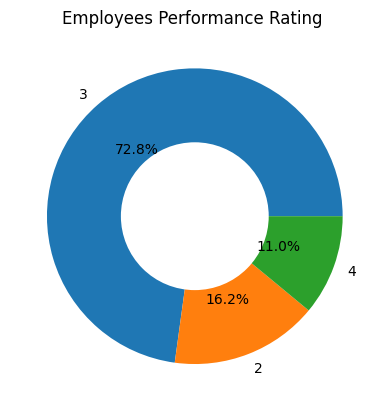

PerformanceRating
3    874
2    194
4    132
Name: count, dtype: int64


In [108]:
# target variable Employeee perfomance Rating
vals = data['PerformanceRating'].value_counts()
labels = vals.index # This will give you the variable names (ratings)
plt.pie(vals, labels=labels, autopct='%1.1f%%')
centre = plt.Circle((0,0),0.5,fc='white')
plt.gca().add_artist(centre)
plt.title('Employees Performance Rating ')
plt.show()

#target variable Employeee perfomance Rating
vals = data['PerformanceRating'].value_counts()
print (vals)

#The majority of the data, according to performance ratings, Excellent (72.8%), Good (16.2%), Outstanding (11.0%) respectively. Overall, most of the performance ratings fell within the excellent category.

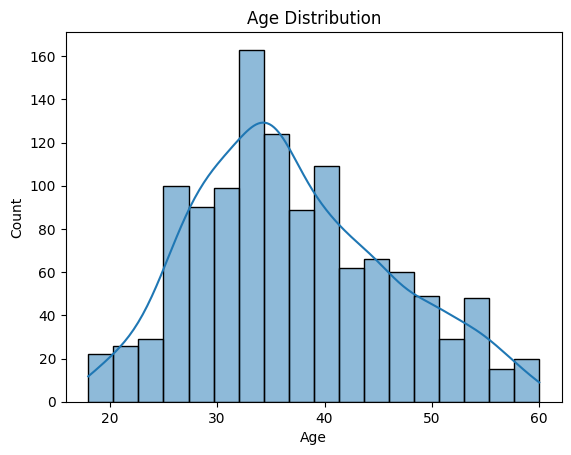

In [109]:
#Age Distributions
plt.figure()
sns.histplot(data['Age'], kde=True)
plt.title('Age Distribution')
plt.show()

##The majority of employees are concentrated in their early 30s, with around age 32 being the most common.
##Employee counts gradually decrease beyond the mid-30s, with fewer staff in their 40s, 50s, and approaching 60.
##Strong representation of younger employees may mean high potential for long-term growth

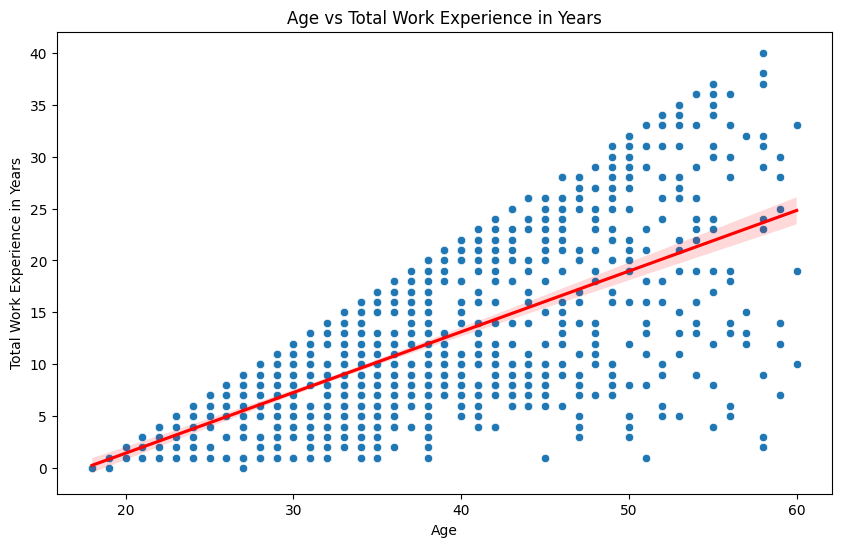

In [110]:
#Age vs years of experience
plt.figure(figsize=(10,6))
sns.scatterplot(x='Age', y='TotalWorkExperienceInYears', data=data)
sns.regplot(x='Age', y='TotalWorkExperienceInYears', data=data, scatter=False, color='red')  # Add a regression line
plt.xlabel('Age')
plt.ylabel('Total Work Experience in Years')
plt.title('Age vs Total Work Experience in Years')
plt.show()

There is a strong, linear relationship between Age and Total Work Experience. As age increases, the total years of work experience generally increase.

The workforce spans from roughly 18 to 60 years old.

Experience Variance: While the trend is upward, there is significant variance.
For example, at age 50, some individuals have 30+ years of experience, while others have fewer than 5 years, likely indicating career changers or those who entered the workforce later.

While many employees have been in their current role for only 2–3 years, the scatter plot shows that many of these individuals are older and possess significantly higher total work experience (up to 40 years). This suggests the organization has a healthy mix of internal mobility and experienced external hires.

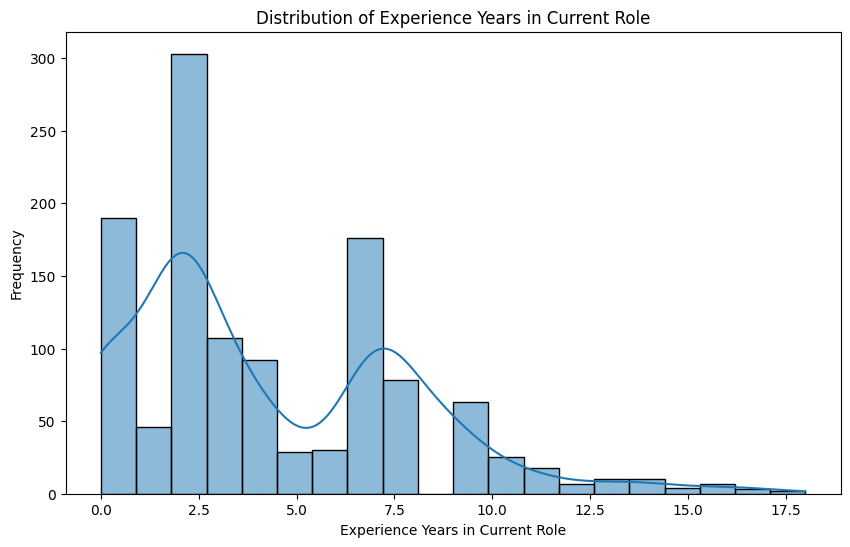

In [111]:
#ExperienceYearsInCurrentRole distributions
plt.figure(figsize=(10,6))
sns.histplot(data['ExperienceYearsInCurrentRole'], kde=True)
plt.title('Distribution of Experience Years in Current Role')
plt.xlabel('Experience Years in Current Role')
plt.ylabel('Frequency')
plt.show()

Highest Density: The most significant cluster of employees falls between 2 and 3 years of experience. This specific bin reaches a frequency of over 300 employees, the highest in the entire dataset.

Implication: This suggests a period of heavy recruitment approximately two to three years ago or a high retention rate for those who have moved past the initial 1-year mark.

There is a clear "valley" around 5 years, suggesting that employees often leave the role or move internally before hitting their sixth year.

A second, smaller peak occurs around 7 to 8 years of experience. This group accounts for roughly 175 employees at its highest point.

These individuals represent the "institutional backbone" employees who have stayed long enough to gain deep expertise but haven't yet reached the "veteran" tail of the curve.

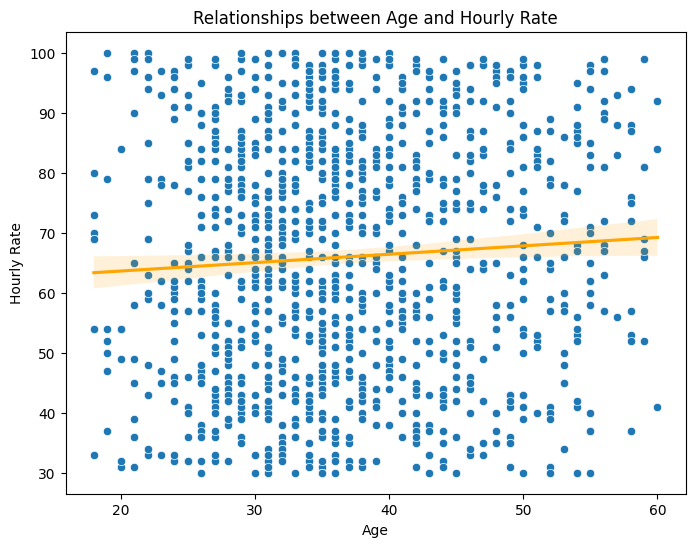

In [112]:
#Relationships between age and salary
plt.figure(figsize=(8,6))
sns.scatterplot(x='Age', y='EmpHourlyRate', data=data)
sns.regplot(x='Age', y='EmpHourlyRate', data=data, scatter=False, color='Orange')
plt.title('Relationships between Age and Hourly Rate')
plt.xlabel('Age')
plt.ylabel('Hourly Rate')
plt.show()

There is slightly relationship between the age and hourly work rate as shown above. there is slightly from roughly 64/hr at age 20 to $69/hr at age 60.

At almost every age point, pay ranges drastically from a floor of 30/hr to 100/hr.

This suggests that in this organization, pay is likely determined by role, performance, or specialized skills rather than simply by seniority or age.

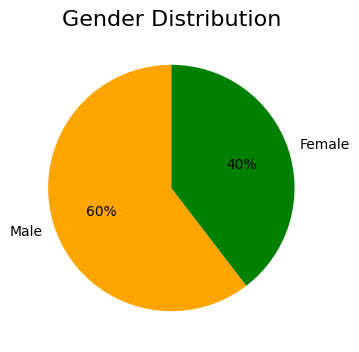

In [113]:
# Pie chart for Gender distribution
data['Gender'].value_counts().plot.pie(
    figsize=(4, 4),
    autopct='%1.0f%%', # show percentages
    colors=['orange', 'green'],  # vivid custom colors (Female, Male)
    startangle=90,            # start from top
)

plt.title('Gender Distribution', fontsize=16)
plt.ylabel('')  # remove default y-label for aesthetics
plt.show()



#According to the Gender, majority were male with 60% while Female at 40%. this suggest that majority employee are males

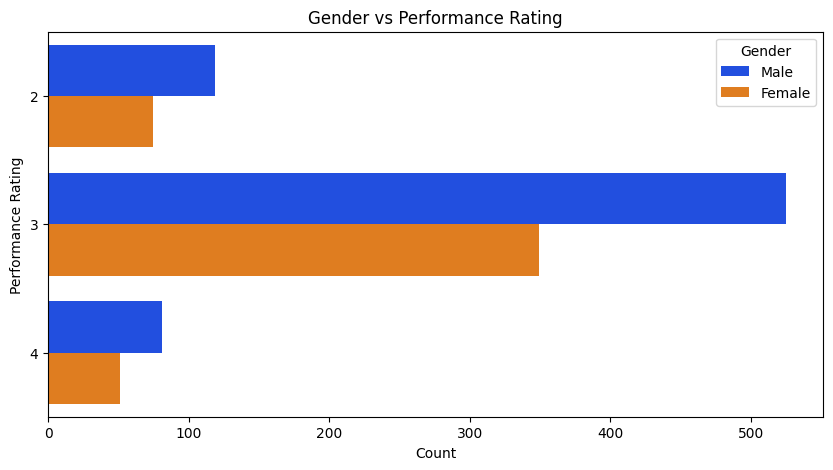

In [114]:
#Gender vs Perfomance chart
plt.figure(figsize=(10,5))
sns.countplot(y='PerformanceRating', hue='Gender', data=data, palette='bright')

plt.title('Gender vs Performance Rating')
plt.xlabel('Count')
plt.ylabel('Performance Rating')

plt.show()

##Majority perfoming according to the gender were male with many rated as excellent

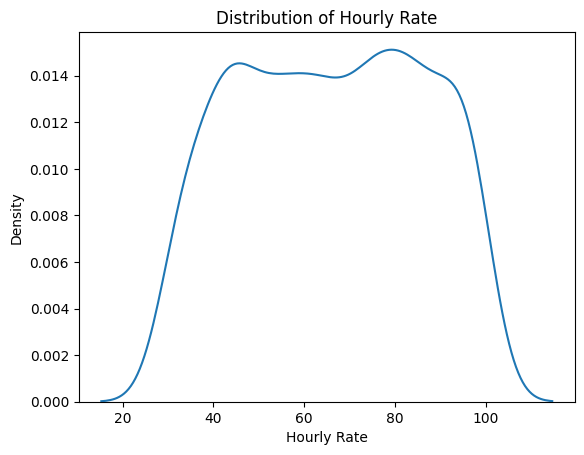

In [115]:
#KDE Plot
sns.kdeplot(data['EmpHourlyRate'])
plt.title('Distribution of Hourly Rate')
plt.xlabel('Hourly Rate')
plt.ylabel('Density')
plt.show()

##Majority employees eanerd their hourly rate between 40 and 90 per hour, since there is high

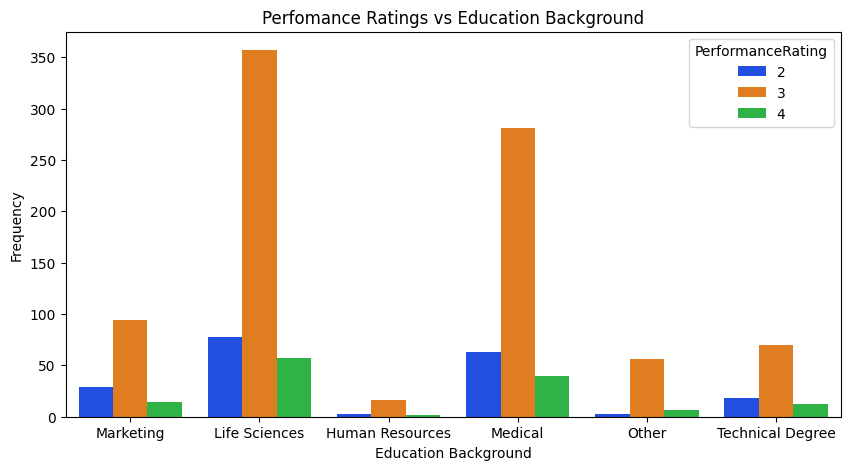

In [116]:
#performance rating vs education background
plt.figure(figsize=(10,5))
sns.countplot(x='EducationBackground',hue='PerformanceRating', data=data,  palette='bright')
plt.title('Perfomance Ratings vs Education Background')
plt.ylabel('Frequency')
plt.xlabel('Education Background')
plt.show()

##Life Sciences employees have the highest number of medium (rating 3) and high (rating 4) performers, making them the strongest group overall.


##Medical and Marketing backgrounds also show more employees in the medium rating (3), with fewer high performers (4).


##Human Resources and Other backgrounds have very few employees overall, mostly concentrated in rating 3.

##Technical Degree employees mostly fall in rating 3, with small numbers in ratings 2 and 4.




#Overall Insight

##Most employees across all education backgrounds are rated 3 (Excellent).

##High performance (rating 4) is concentrated in Life Sciences and Medical.

##Low performance (rating 2) is visible across Marketing, Medical, and Technical backgrounds, though less frequent.

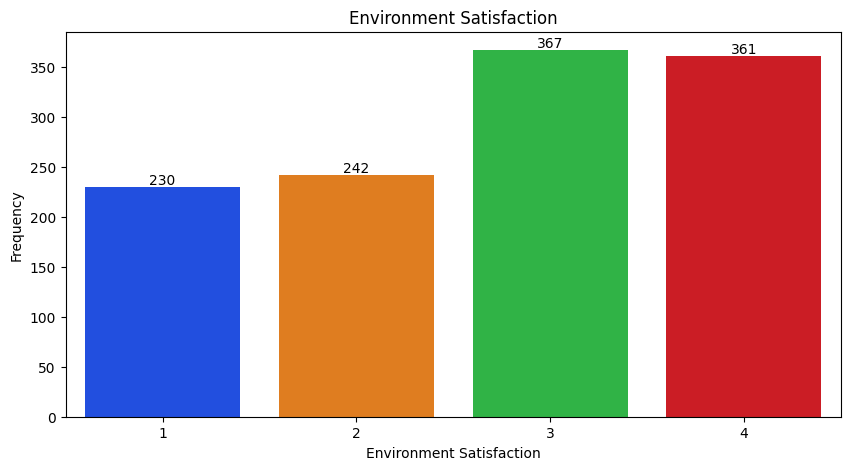

In [117]:
#Bar plot for EmpEnvironmentSatisfaction
plt.figure(figsize=(10,5))
ax=sns.countplot(x='EmpEnvironmentSatisfaction', data=data, palette='bright')
plt.title('Environment Satisfaction')
plt.ylabel('Frequency')
plt.xlabel('Environment Satisfaction')

for p in ax.containers:
    ax.bar_label(p)

plt.show()

##Most employees are satisfied with the environment, with high (3) and very high (4) satisfaction accounting for the majority (~728 employees).

##Only a smaller portion of employees report low or medium satisfaction (~472 employees combined).

##This suggests that overall workplace environment is positively perceived, which could be leveraged to improve performance and morale.

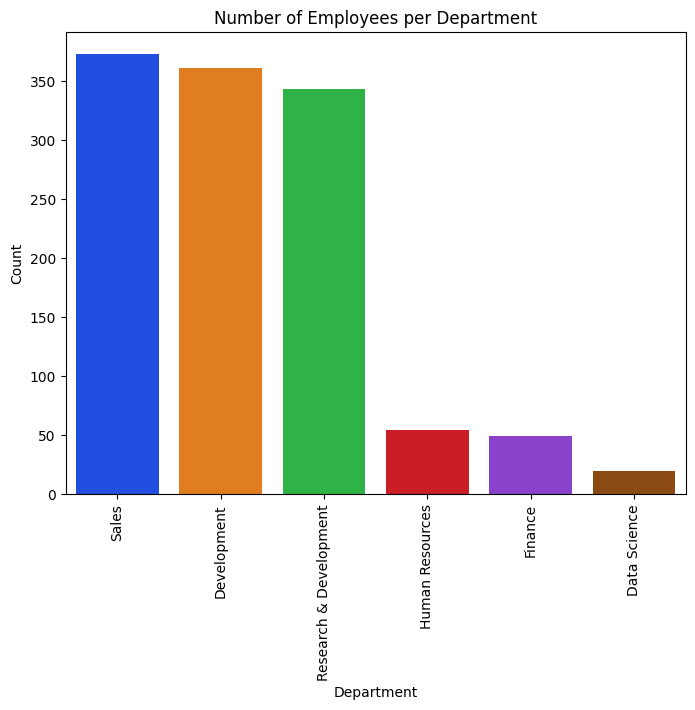

In [118]:
#EmpDepartment
plt.figure(figsize=(8,6))
dept_order = data['EmpDepartment'].value_counts().index

sns.countplot(x='EmpDepartment',data=data,order=dept_order,palette='bright')
plt.title('Number of Employees per Department')
plt.ylabel('Count')
plt.xlabel('Department')
plt.xticks(rotation=90)

plt.show()

##the employee distribution shows that the organization’s workforce is heavily concentrated in Sales, Development, and Research & Development, indicating a strong focus on revenue generation and product innovation. In contrast, support and analytical departments such as Human Resources, Finance, and Data Science have significantly fewer employees, suggesting a lean structure in administrative and data-focused functions.

##The company appears to prioritize sales performance and product development, with lean staffing in administrative and analytical functions

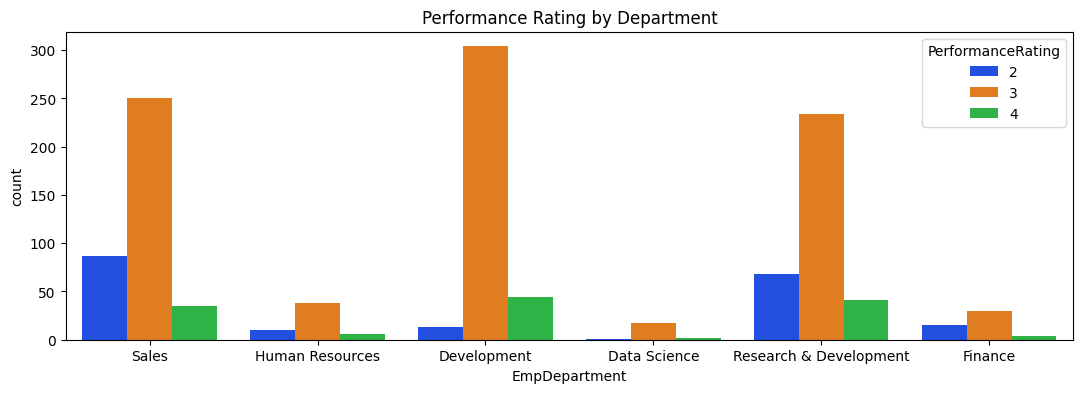

In [119]:
#Perfomance Rating by Departments
plt.figure(figsize=(13,4))
sns.countplot(x='EmpDepartment', hue='PerformanceRating', data=data, palette='bright')
plt.title('Performance Rating by Department')
plt.show()

## Rating 3 (Excellent) is the dominant performance level across all departments.

## Rating 2 (Good) is moderate in some departments, especially Sales and R&D.

## Rating 4 (Outstanding) is the least common in every department.

# The company demonstrates a strong performance culture, with most employees rated Excellent (3). However, the proportion of Outstanding (4) performers is relatively low across all departments, suggesting potential opportunities for performance development and recognition programs.

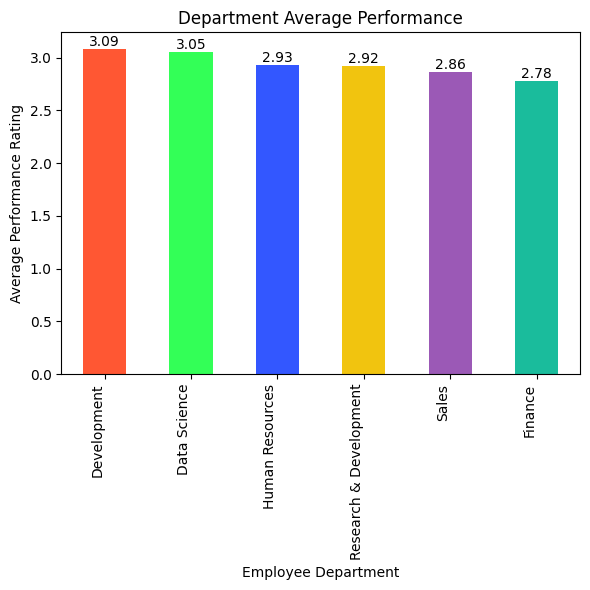

In [120]:
# Department Average Performance
vals = data.groupby('EmpDepartment')['PerformanceRating'].mean()
vals = vals.sort_values(ascending=False)

plt.figure(figsize=(6, 6))
ax=vals.plot.bar(color=['#FF5733', '#33FF57', '#3357FF', '#F1C40F', '#9B59B6', '#1ABC9C'])
plt.title("Department Average Performance")
plt.ylabel("Average Performance Rating")
plt.xlabel("Employee Department")
plt.xticks(rotation=90, ha='right')
plt.tight_layout()

for p in ax.containers:
    ax.bar_label(p, fmt='%.2f')
plt.show()

###The differences across departments are relatively small, with only a 0.3 spread between the highest and lowest performers.

###Development and Data Science are slightly ahead, suggesting stronger performance consistency.

###Finance may need targeted support or interventions to raise its average closer to the organizational benchmark.

##The clustering of HR and R&D at 2.9 indicates similar performance challenges or comparable evaluation standards.

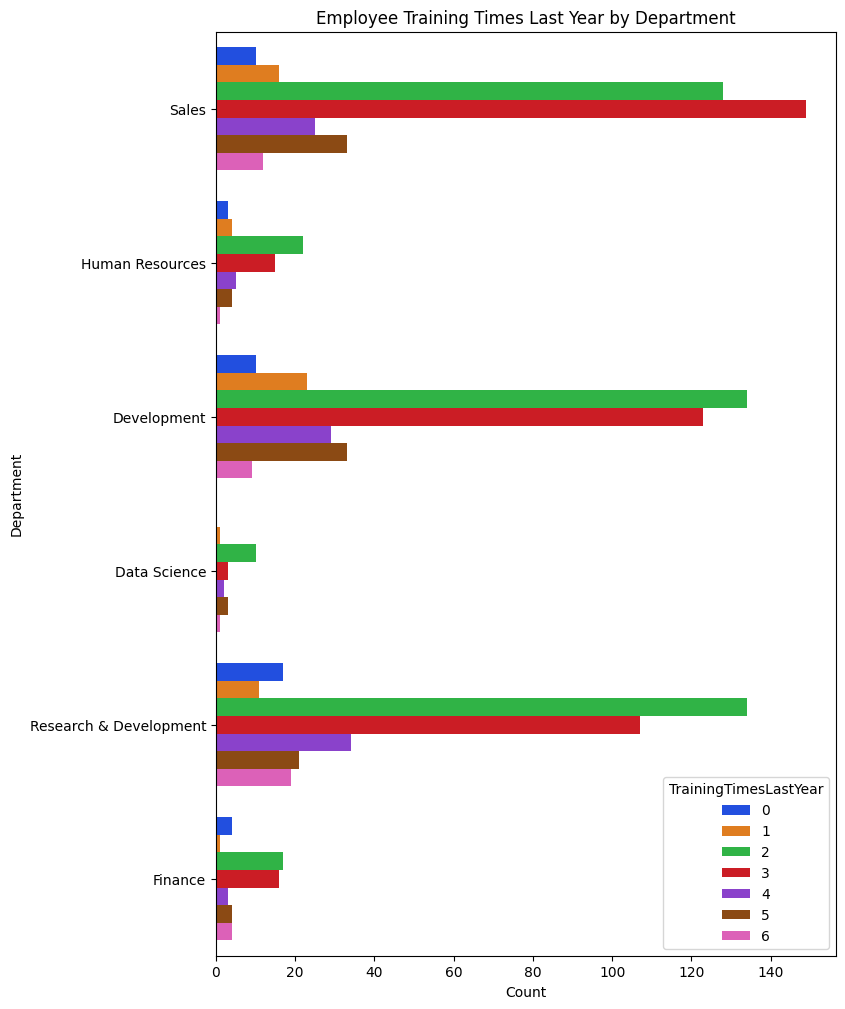

In [121]:
#TrainingTimesLastYear per department
plt.figure(figsize=(8,12))
sns.countplot(y='EmpDepartment', hue='TrainingTimesLastYear', data=data, palette='bright')
plt.title('Employee Training Times Last Year by Department')
plt.xlabel('Count')
plt.ylabel('Department')
plt.show()

Sales department- Majority employees were trained 3 times and 2 times last year
Development and Research Development, the hishest number of trained employees were those who trained 2 times, followed by the 2 times
Human Resource, Data science and Finance few attended trainings, therefore majority still follows 2 times and 3 times trainings

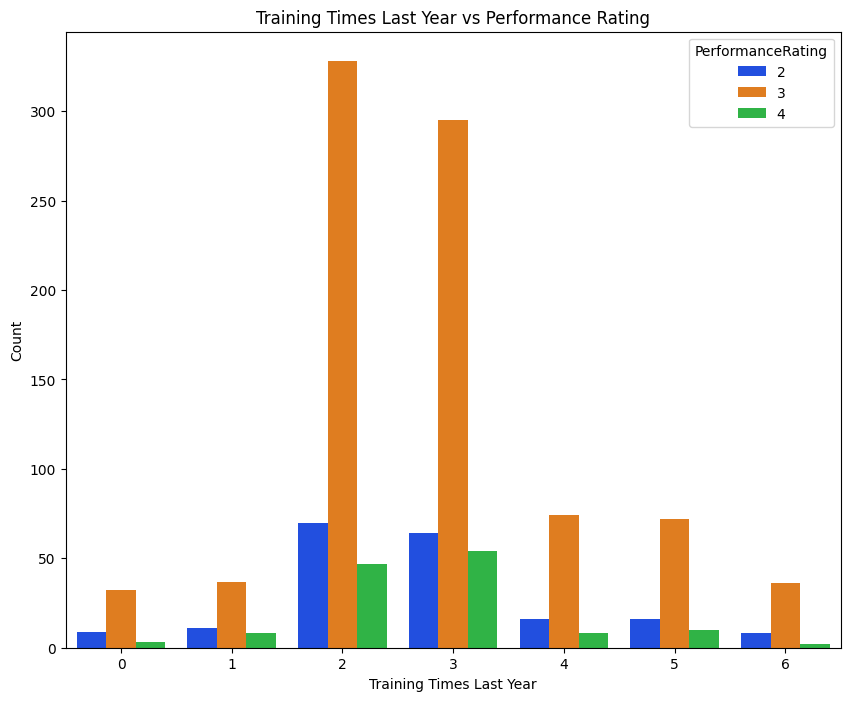

In [122]:
#TrainingTimesLastYear by perfomance ratings
plt.figure(figsize=(10,8))
sns.countplot(x='TrainingTimesLastYear', hue='PerformanceRating', data=data, palette='bright')
plt.title('Training Times Last Year vs Performance Rating')
plt.ylabel('Count')
plt.xlabel('Training Times Last Year')
plt.show()



The highest counts are at 2 and 3 training sessions.
Employees with Performance Rating 4 appear mostly among those trained 2–3 times.
Very few employees with 0 or 6 trainings achieve rating 4.
For every number of training sessions (0–6), Rating 3 has the highest count.
This suggests the organization has a large proportion of average performers.

There appears to be a moderate positive relationship between training frequency (especially 2–3 sessions) and better performance ratings. However: Increasing training beyond 3 sessions (4–6) does not clearly increase high performance (rating 4).

The relationship is not strongly linear.

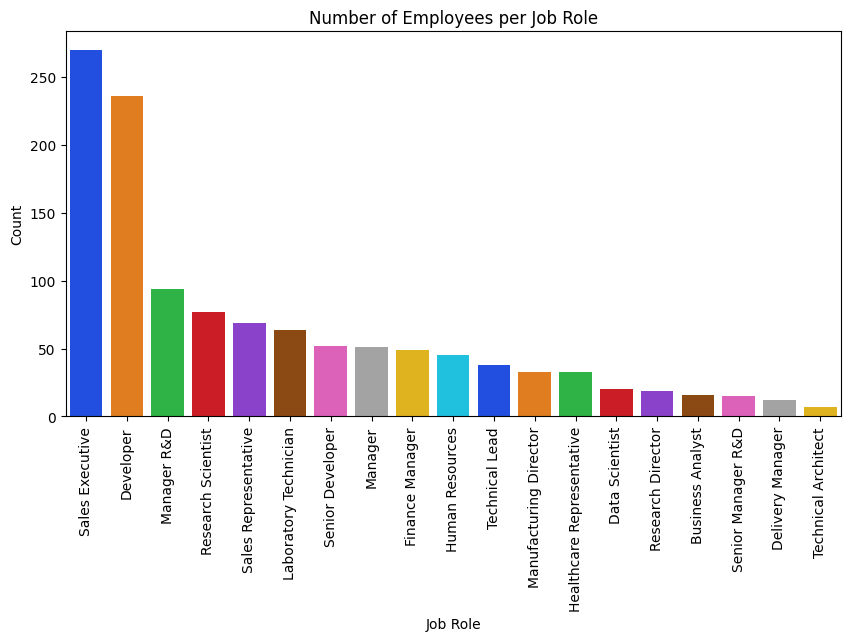

In [123]:
#EmpJobRole
plt.figure(figsize=(10,5))
job_order = data['EmpJobRole'].value_counts().index
sns.countplot(x='EmpJobRole',data=data,order=job_order,palette='bright')
plt.title('Number of Employees per Job Role')
plt.ylabel('Count')
plt.xlabel('Job Role')
plt.xticks(rotation=90)
plt.show()



##Majority of employees are sales Executive, followerd by Developers and least being technical archtets this suggest that the company sales are more

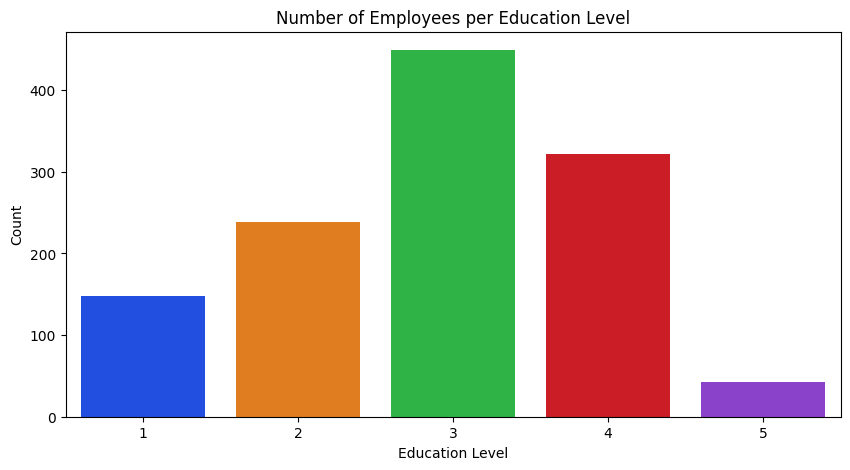

In [124]:
#EmpEducationLevel
plt.figure(figsize=(10,5))
sns.countplot(x='EmpEducationLevel',data=data,palette='bright')
plt.title('Number of Employees per Education Level')
plt.ylabel('Count')
plt.xlabel('Education Level')
plt.show()

##The majority of employees hold a Bachelor’s degree, followed by those with a Master’s degree, while the Doctorate level is the least represented.

#**What does This means**
##The organization’s talent pool is heavily concentrated at the undergraduate level, which is typical in many industries where a Bachelor’s degree is the standard entry requiremen

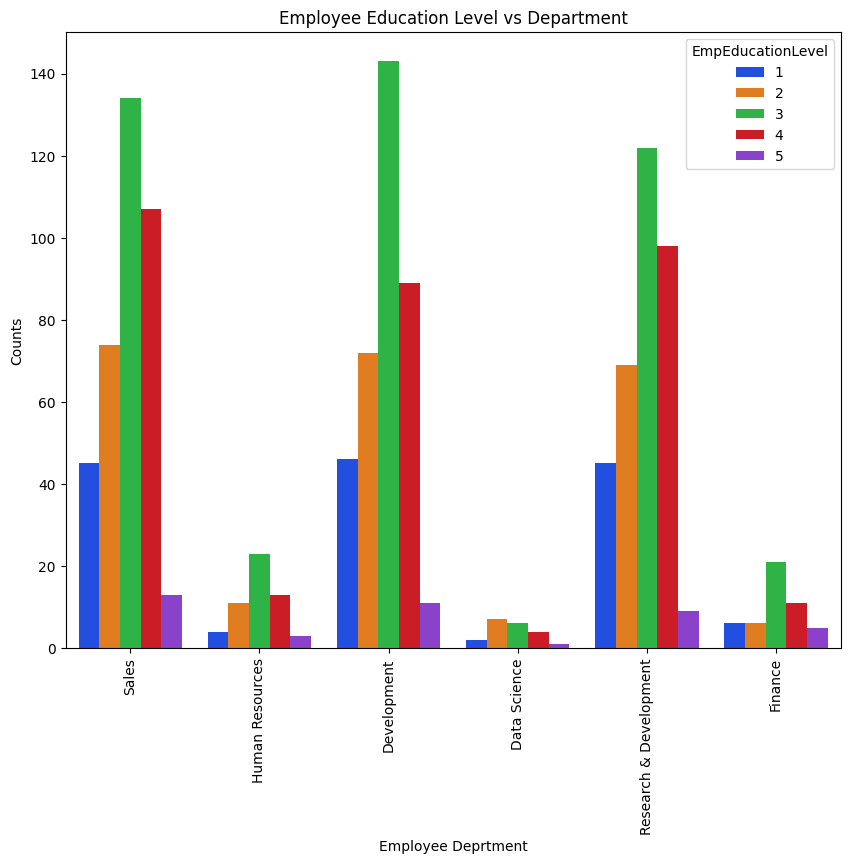

In [125]:
#Employee education level vs department
plt.figure(figsize=(10,8))
sns.countplot(x='EmpDepartment',hue='EmpEducationLevel', data=data,  palette='bright')
plt.title('Employee Education Level vs Department')
plt.ylabel('Counts')
plt.xlabel('Employee Deprtment')
plt.xticks(rotation=90)
plt.show()

## Bachelor’s degree (Level 3) is the most common qualification across all departments.

## Master’s degree (Level 4) is the second most common.

##Very few employees have Doctorates (Level 5).

##Employees with Below College (Level 1) education are moderate in large departments but very few in technical units.

## The organization is largely composed of employees with Bachelor’s degrees, especially in technical departments like Development and R&D. Higher academic qualifications (Master’s and Doctorates) are more concentrated in technical and research-focused departments, while lower education levels are minimal across the company.

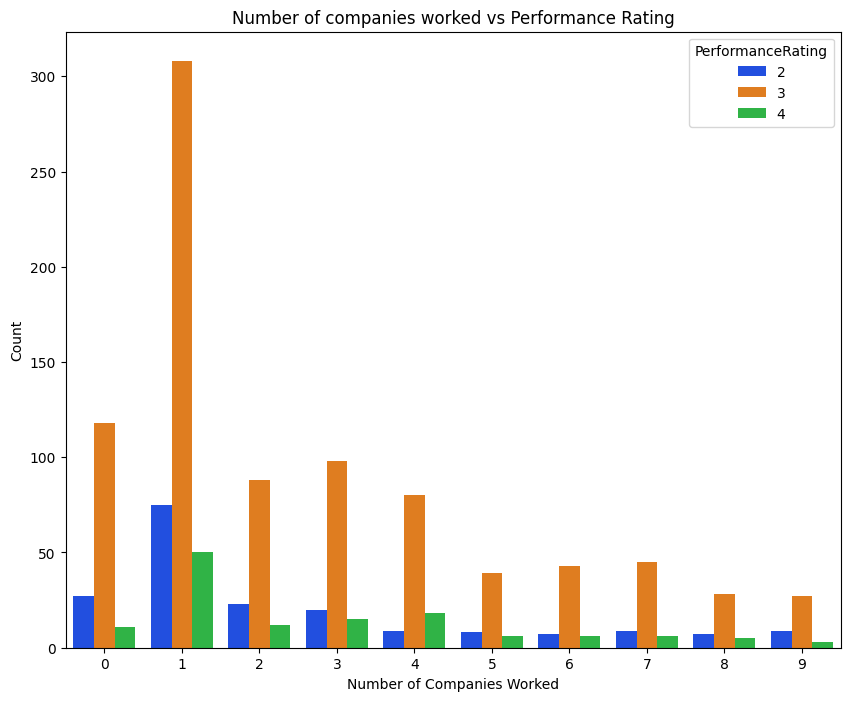

In [126]:
#NumCompaniesWorked vs performance Ratings
plt.figure(figsize=(10,8))
sns.countplot(x='NumCompaniesWorked', hue='PerformanceRating', data=data, palette='bright')
plt.title('Number of companies worked vs Performance Rating')
plt.ylabel('Count')
plt.xlabel('Number of Companies Worked')
plt.show()

##**Dominant Performance Rating:** Across almost all experience levels, a Performance Rating of 3 (Excellent) is the most common.

##**Peak Performance Volume**: The highest concentration of top performers occurs among those with one prior company, peaking at over 300 employees with a rating of 3.

##**High Achievers (Rating 4 - Outstanding):** These employees are less common but present at every experience level, with slight concentrations among those who have worked at 1 or 4 previous companies.

#**Key Note:** Having worked at a high number of companies (5–9) does not correlate with higher performance ratings; in fact, the total count of employees in these brackets drops significantly.

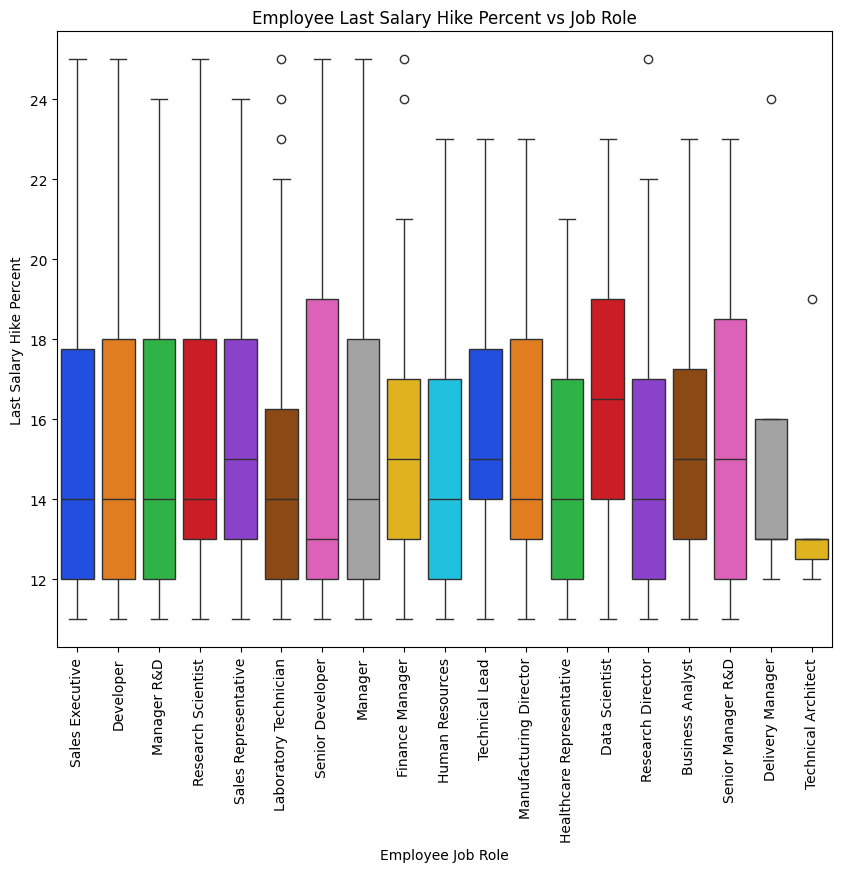

In [127]:
#EmpLastSalaryHikePercent vs Job role
plt.figure(figsize=(10,8))
job_order = data['EmpJobRole'].value_counts().index
sns.boxplot(x='EmpJobRole', y='EmpLastSalaryHikePercent', data=data,order=job_order, palette='bright')
plt.title('Employee Last Salary Hike Percent vs Job Role')
plt.ylabel('Last Salary Hike Percent')
plt.xlabel('Employee Job Role')
plt.xticks(rotation=90)
plt.show()


###Top Growth Roles: Data Scientists see the highest median salary hikes at approximately 16.5%

###Standardized Compensation: Most core roles including  Sales Executives, and Managers receive a median hike clustered around 14%.

###Conservative Hikes: Technical Architects receive the most compressed and lowest hikes, generally between 12% and 13%.

##Exceptional Adjustments: Some roles like Laboratory Technician and Research Director have "outlier" hikes reaching as high as 25%.

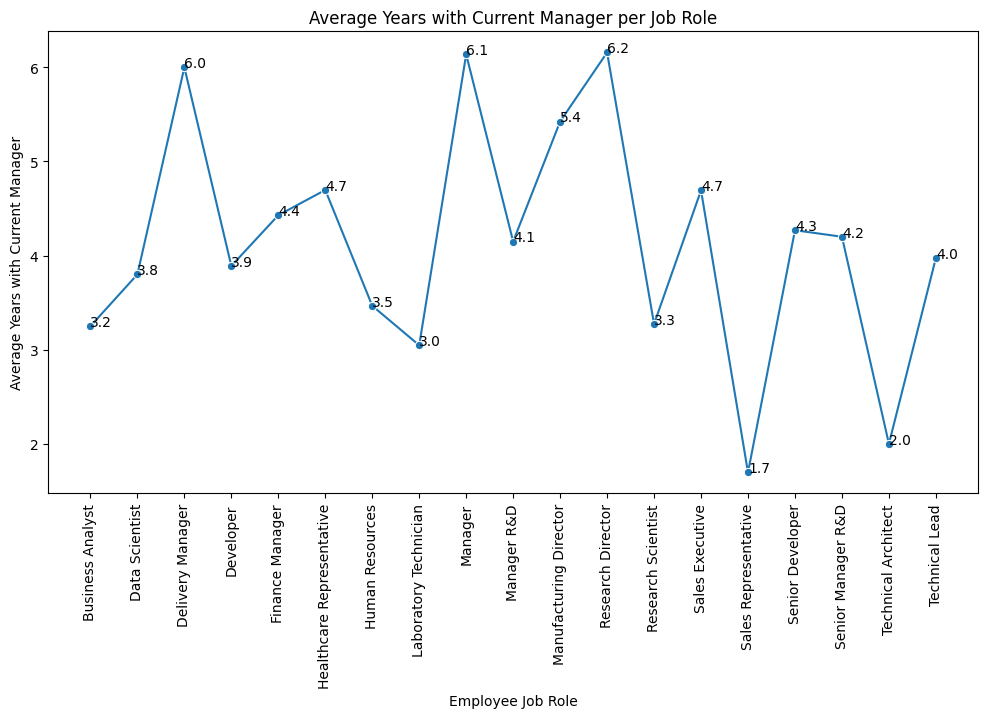

In [128]:
# YearsWithCurrManager vs emjobrole line plot average
avg_manager_years = data.groupby('EmpJobRole')['YearsWithCurrManager'].mean().reset_index()
plt.figure(figsize=(12,6))

ax = sns.lineplot(x='EmpJobRole',y='YearsWithCurrManager',data=avg_manager_years,marker='o')

# Add data labels
for i, row in avg_manager_years.iterrows():
    ax.text(i, row['YearsWithCurrManager'], round(row['YearsWithCurrManager'], 1), ha='left')

plt.title('Average Years with Current Manager per Job Role')
plt.xlabel('Employee Job Role')
plt.ylabel('Average Years with Current Manager')
plt.xticks(rotation=90)

plt.show()

## Highest Manager Tenure: Research Director (6.2 years), Manager (6.1 years), and Delivery Manager (6.0 years) show the strongest manager-employee relationships.
## Lowest Manager Tenure: Sales Representative (1.7 years) and Technical Architect (2.0 years) have the shortest time with their current managers, indicating potential turnover or restructuring issues.
## Leadership and director-level roles maintain longer manager relationships compared to entry-level and technical positions, suggesting better stability at senior levels.

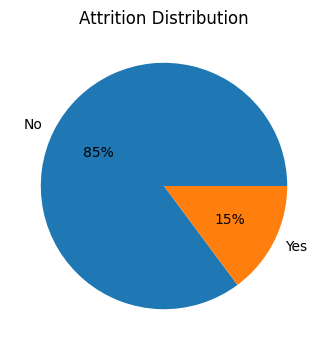

In [129]:
#Atritions Distriputions
plt.figure(figsize=(4,4))
counts = data['Attrition'].value_counts()

plt.pie(counts,labels=counts.index, autopct='%1.0f%%')
plt.title('Attrition Distribution')
plt.show()

##**No (Retained)-85%,** Represents the stable core of the company.
## **Yes(Attrited)-15%**, Represents employees who have left the company.

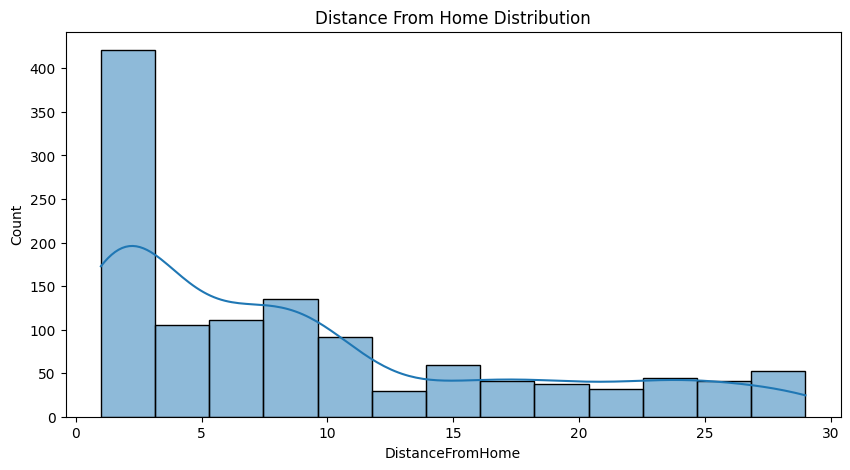

In [130]:
#Distance from home Distributions
plt.figure(figsize=(10,5))
sns.histplot(data['DistanceFromHome'], kde=True)
plt.title('Distance From Home Distribution')
plt.show()

###This is right skewed distributions or positive skewed ditributions
###There is a massive spike at the very beginning of the scale. Over 400 employees live within a very short distance from the office.

###The Mid-Range Drop-off: Once you move past the 10 mark, the numbers drop significantly. Most of your staff seems to prioritize a short commute.

###The Commuter Tail, There is a thin but steady "tail" extending all the way to 30. While these employees are fewer in number, they represent the group most at risk for "commute burnout," which often correlates with the 15% attrition rate we saw earlier.

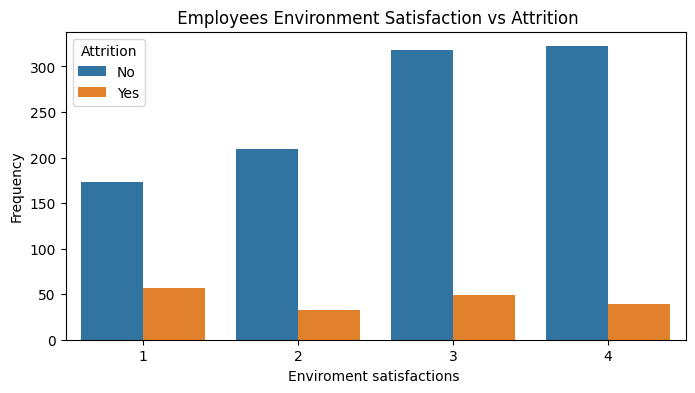

In [131]:
#Environment Satisfaction vs Attrition
plt.figure(figsize=(8,4))
sns.countplot(x='EmpEnvironmentSatisfaction', hue='Attrition', data=data)
plt.title(' Employees Environment Satisfaction vs Attrition')
plt.ylabel('Frequency')
plt.xlabel('Enviroment satisfactions ')
plt.show()

###The "At-Risk" Group ( 1): Employees with the lowest environment satisfaction show the highest relative attrition, with nearly 60 employees leaving in this category.

###Retention Sweet Spot (3 & 4): Employees who report high satisfaction (3 and 4) are much more likely to stay, with over 300 employees in each of these categories remaining at the company.

## Even though there are far more employees in the high-satisfaction groups, the total number of departures (Yes) is visibly lower in 3 and 4 than in the dissatisfied 1.

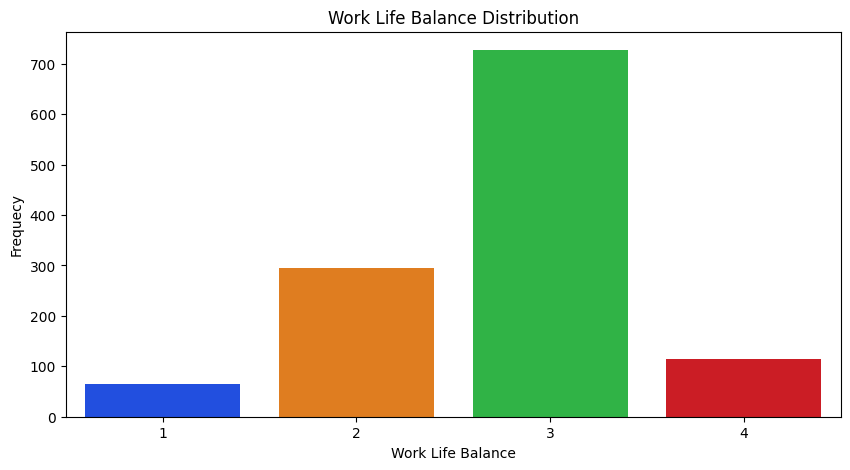

In [132]:
#Work Life Balance Distribution
plt.figure(figsize=(10,5))
sns.countplot(x='EmpWorkLifeBalance', data=data, palette='bright')
plt.title('Work Life Balance Distribution')
plt.xlabel('Work Life Balance')
plt.ylabel('Frequecy')
plt.show()

##The "Better" Majority: 3 ('Better') is the most frequent rating, with over 700 employees.

##Moderate Balance: Roughly 300 employees feel their work-life balance is 2 ('Good').

###The Extremes: A small segment of the population experiences either a 1 ('Bad') balance (approx. 70 employees) or a 4 ('Best') balance (approx. 110 employees).

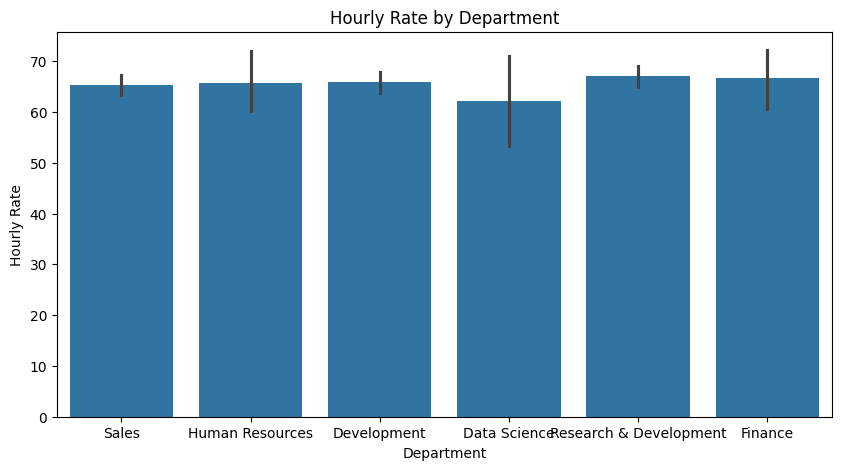

In [133]:
#hourl rate by departmets
plt.figure(figsize=(10,5))
sns.barplot(x='EmpDepartment', y='EmpHourlyRate', data=data)
plt.title('Hourly Rate by Department')
plt.xlabel('Department')
plt.ylabel('Hourly Rate')
plt.show()

## Hourly pay across departments is relatively uniform, with R&D and Finance slightly leading, while Data Science has the lowest average rate. The small differences suggest structured pay grading rather than large departmental salary gaps.

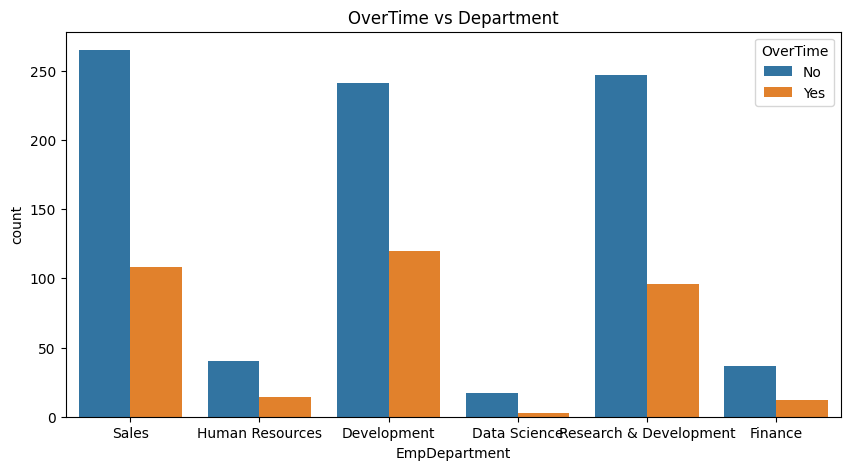

In [134]:
#OverTime vs department
plt.figure(figsize=(10,5))
sns.countplot(hue='OverTime', x='EmpDepartment', data=data)
plt.title('OverTime vs Department')
plt.show()

## Across all the department , majority of the employees doesnt work on the overtime

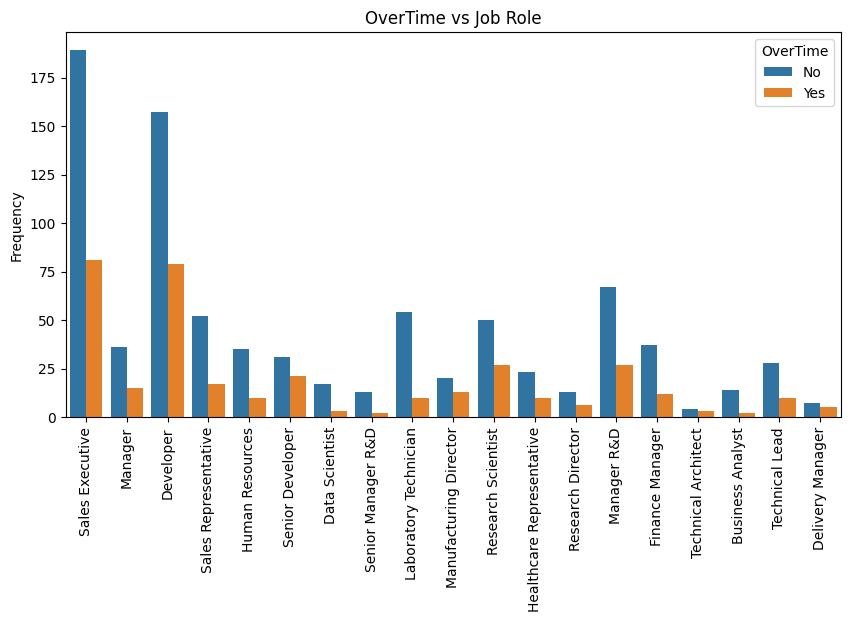

In [135]:
#Over time vs Job role
plt.figure(figsize=(10,5))
sns.countplot(hue='OverTime', x='EmpJobRole', data=data)
plt.title('OverTime vs Job Role')
plt.ylabel('Frequency')
plt.xlabel('')
plt.xticks(rotation=90)
plt.show()

###Sales Executives and Developers have the highest frequency of employees both working and not working overtime.

###For Sales Executives, nearly 80 employees regularly work overtime, while over 180 do not.

###Roles like Data Scientists and Senior Managers R&D show very low overtime requirements, with fewer than 5–10 employees in those roles reporting "Yes" for overtime.

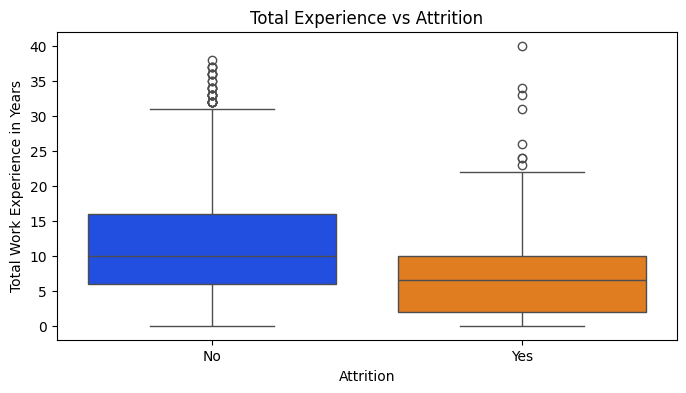

In [136]:
# experience vs attrition
plt.figure(figsize=(8,4))
sns.boxplot(x='Attrition', y='TotalWorkExperienceInYears', data=data,palette='bright')
plt.title('Total Experience vs Attrition')
plt.xlabel('Attrition')
plt.ylabel('Total Work Experience in Years')
plt.show()

Employees who stay with the company ("No" Attrition) have a notably higher median work experience—roughly 10 years—compared to those who leave ("Yes" Attrition), whose median is approximately 7 years.

The Early Career Risk Zone,  The "Yes" group's interquartile range  is concentrated between 2 and 10 years of experience. This suggests that employees in their first decade of total work experience are more likely to depart.

The risk of losing an employee is significantly higher during their first 10 years of total career experience

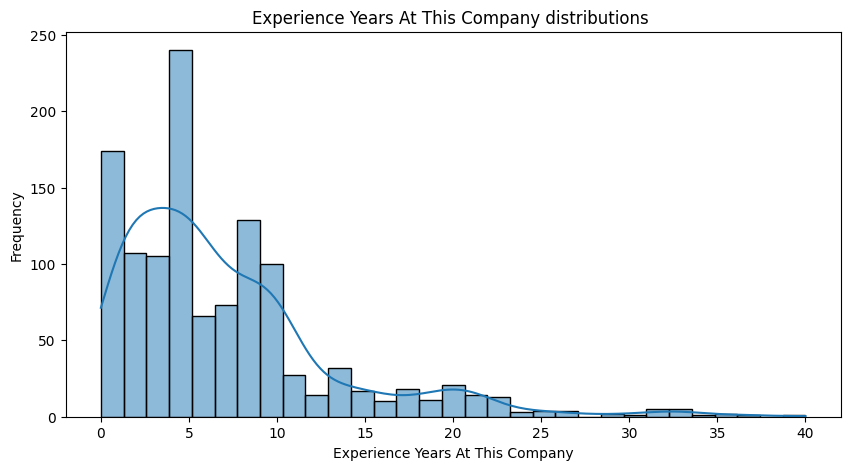

In [137]:
#Experience Years At This Company distributions
plt.figure(figsize=(10,5))
sns.histplot(data['ExperienceYearsAtThisCompany'], kde=True)
plt.title('Experience Years At This Company distributions ')
plt.xlabel('Experience Years At This Company')
plt.ylabel('Frequency')
plt.show()

Peak Tenure: The highest frequency of employees occurs at approximately 5 years of experience at the company, with over 240 individuals in this category.

Early Career Concentration: The workforce is heavily weighted toward newer staff, with the largest volume of employees falling between 0 and 10 years of tenure.

Initial Entry: There is a significant initial group of approximately 175 employees with near 0 years of experience, suggesting recent hiring activity.

The "Long Tail": Frequency drops significantly after the 10-year mark. However, the distribution extends as far as 40 years, indicating a small but present group of long-term veterans.

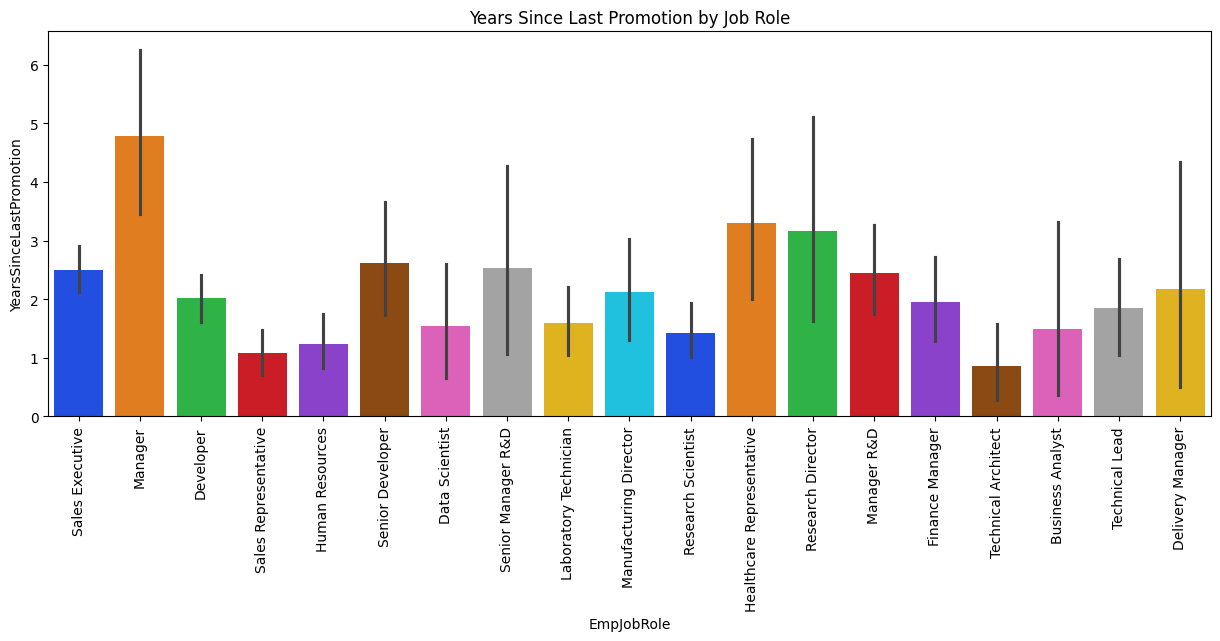

In [138]:
#YearsSinceLastPromotion by Job role
plt.figure(figsize=(15,5))
sns.barplot(x='EmpJobRole', y='YearsSinceLastPromotion',data=data, palette='bright')
plt.title('Years Since Last Promotion by Job Role')
plt.xticks(rotation=90)
plt.show()

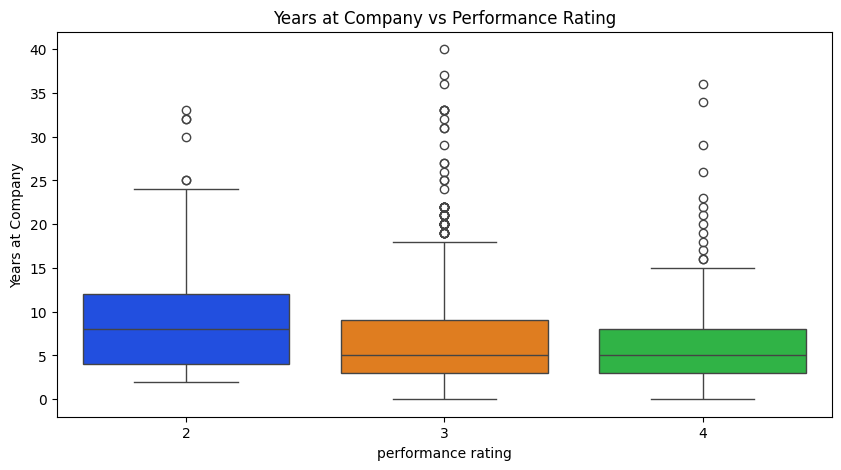

In [139]:
#Years at Company vs perfomance rating
plt.figure(figsize=(10,5))
sns.boxplot(x='PerformanceRating', y='ExperienceYearsAtThisCompany', data=data, palette='bright')
plt.title('Years at Company vs Performance Rating')
plt.xlabel('performance rating')
plt.ylabel('Years at Company')
plt.show()

There is a slight inverse relationship between tenure and performance. Employees with a rating of 2 (the lowest shown) actually tend to have a higher median tenure (around 8 years) compared to those with a rating of 3 or 4 (median tenure around 5 years).

Most high performers (Rating 4) are relatively new employees to the company. The bulk of this group falls between 3 and 8 years of tenure.

The Outliers: All three categories show significant outliers employees who have stayed 20 to 40 years. Interestingly, the Rating 3 category has the highest number of long-tenured outliers, including someone who has been there for 40 years.

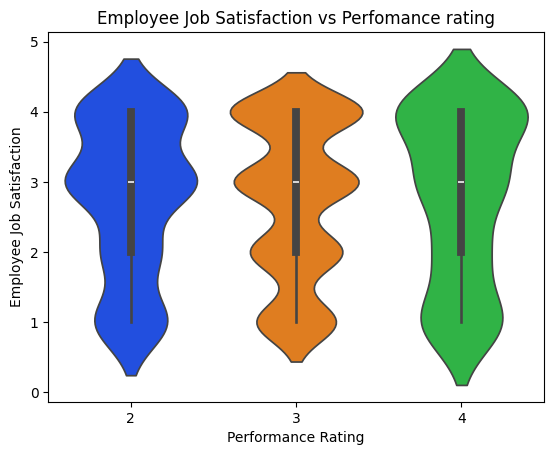

In [140]:
#Employee Job Satisfaction vs Perfomance rating
sns.violinplot(x='PerformanceRating', y='EmpJobSatisfaction', data=data, palette='bright')
plt.title('Employee Job Satisfaction vs Perfomance rating')
plt.xlabel('Performance Rating')
plt.ylabel('Employee Job Satisfaction')
plt.show()

For Ratings 2, 3, and 4, the central tendency appears close to 3. This suggests moderate satisfaction is common regardless of performance rating.

Employees with Performance Rating 4 show: More density at satisfaction 3 and 4.

Fewer extremely low satisfaction values compared to rating 2.

Rating 2 employees show more variation toward lower satisfaction levels.

#**DATA PREPARATIONS**

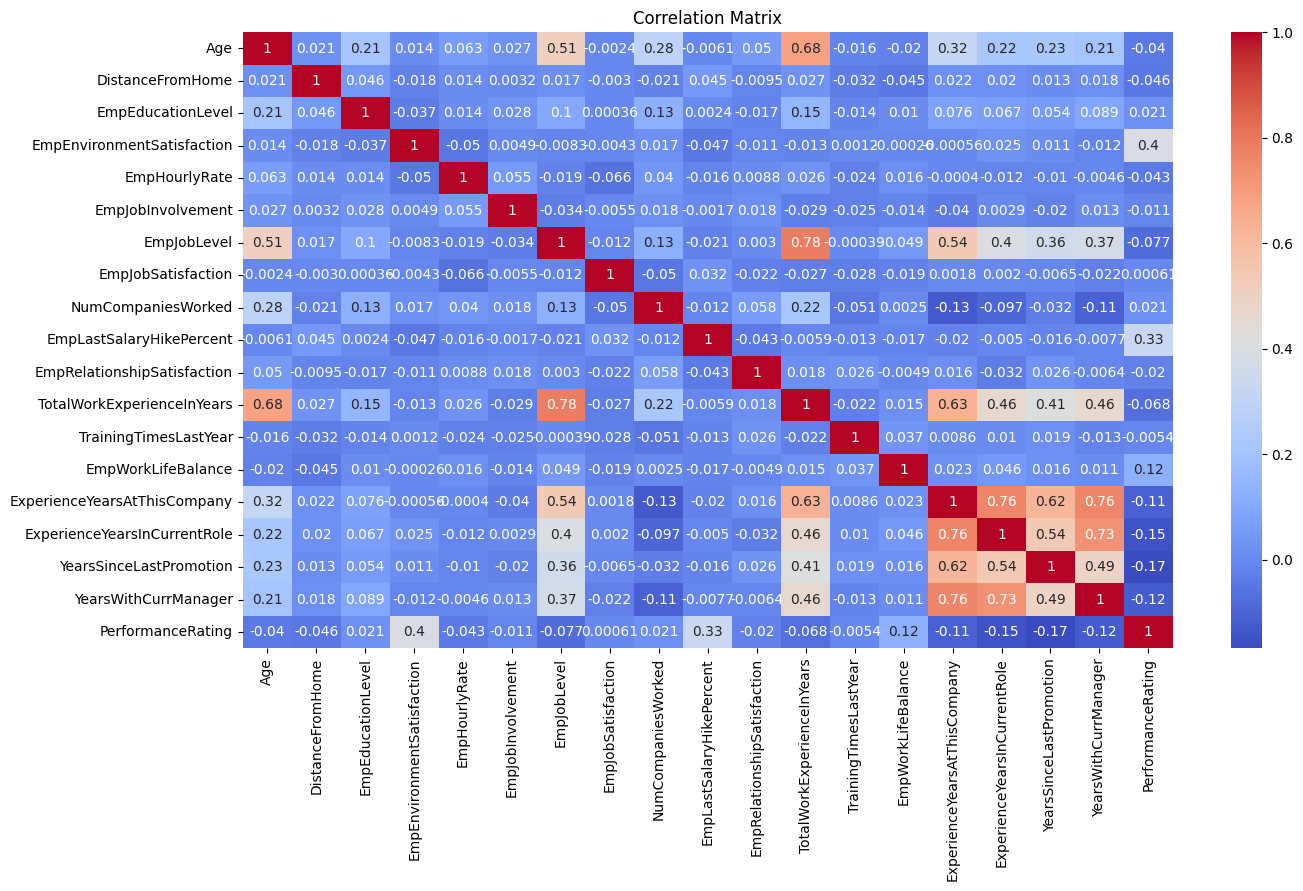

In [141]:
#correlation matrix
plt.figure(figsize=(15,8))
numeric_data=data.select_dtypes(include=['int64','float64'])
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


##HIGH Correlations with PerformanceRating (Target Variable):
Strong predictors:

EmpLastSalaryHikePercent: 0.33

EmpEnvironmentSatisfaction: 0.40

##MEDIUM Correlations:

EmpEducationLevel: 0.021

NumCompaniesWorked: 0.021

##Multicollinearity Issues (Features highly correlated with EACH OTHER):
## These feature pairs are highly correlated:
Experience Features

TotalWorkExperienceInYears - Age: 0.68

TotalWorkExperienceInYears - EmpJobLevel: 0.78

ExperienceYearsAtThisCompany - ExperienceYearsInCurrentRole: 0.76

ExperienceYearsAtThisCompany - YearsSinceLastPromotion: 0.62

ExperienceYearsAtThisCompany - YearsWithCurrManager: 0.76

##These are all measuring similar things.
EmpJobLevel - Age: 0.51

EmpJobLevel - TotalWorkExperienceInYears: 0.78

##Create a copy of dataset for analysis

In [142]:
#copy of dataset
data_copy=data.copy()


In [143]:
# Drop most redundant/useless ones
drop_features = [
    'DistanceFromHome',
    'EmpHourlyRate',
    'EmpJobInvolvement',
    'EmpRelationshipSatisfaction',
    'TrainingTimesLastYear',
    'EmpJobSatisfaction',
    'EmpWorkLifeBalance',
    'TotalWorkExperienceInYears',  # Redundant with EmpJobLevel
    'ExperienceYearsInCurrentRole',  # Redundant with ExperienceYearsAtThisCompany
    'YearsWithCurrManager'  # Weak and redundant
]


In [144]:
data_copy.drop(columns=drop_features, inplace=True,axis=1)
data_copy.drop(columns=['EmpNumber'], inplace=True,axis=1)


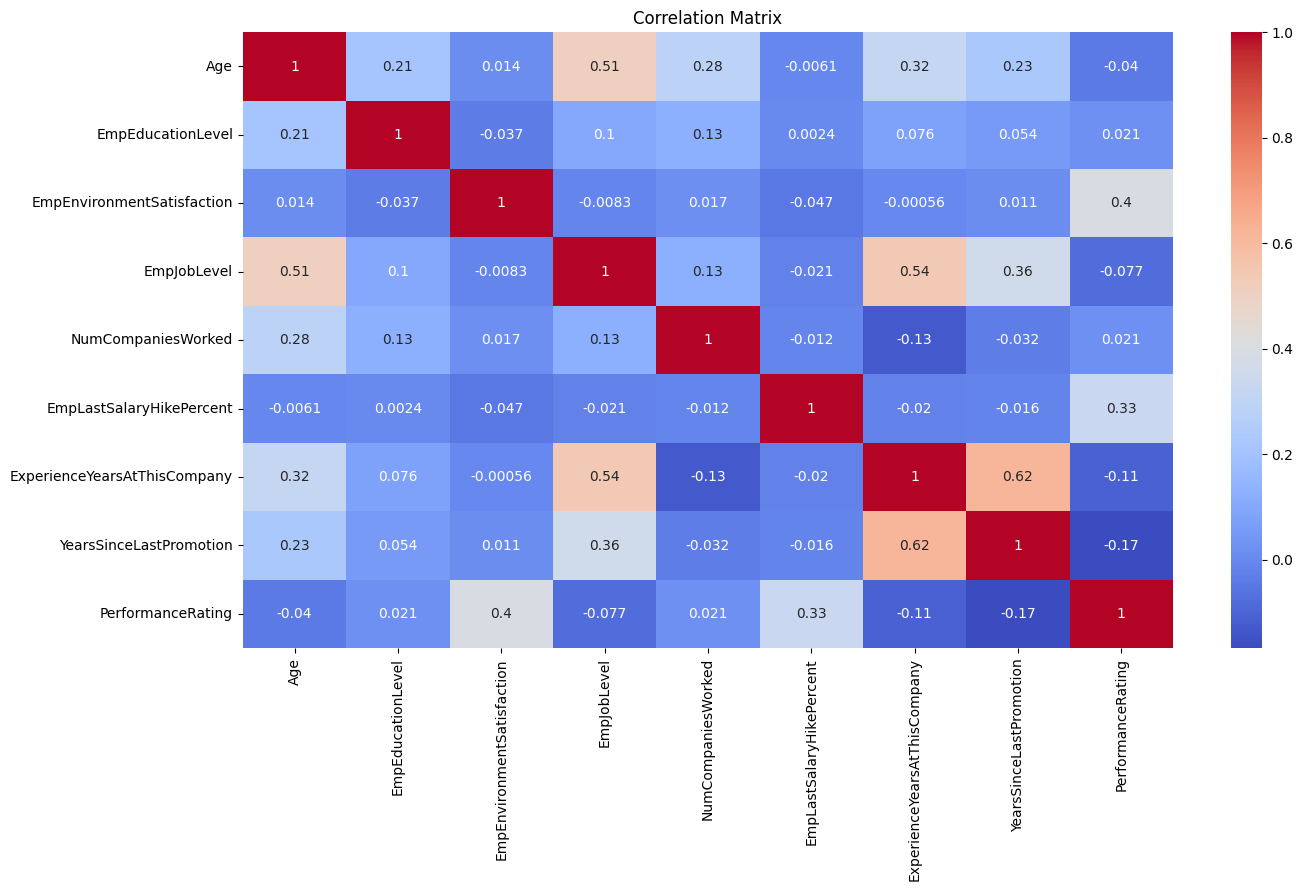

In [145]:
#correlation matrix for data_copy
plt.figure(figsize=(15,8))
numeric_data=data_copy.select_dtypes(include=['int64','float64'])
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

Drop features which are not important in this case

# Outlier Removal using Inter Quartile Range

In [146]:
#Outlier detection and Removal IQR
def remove_outliers_iqr(data_copy,column):
  Q1=data_copy[column].quantile(0.25)
  Q3=data_copy[column].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR
  outliers=data_copy[(data_copy[column]<lower_bound) | (data_copy[column]>upper_bound)]#Outlier detection
  cleaned=data_copy[(data_copy[column]>=lower_bound) & (data_copy[column]<=upper_bound)] #Outlier Removal
  print(f'Outliers detected in {column}: {len(outliers)}')
  print(f"Before: {data_copy.shape}, After removal: {cleaned.shape}")
  return cleaned

In [147]:
#Remove outliers,YearsSinceLastPromotion,numcomponiesworked,EmpLastSalaryHikePercent,TotalWorkExperienceInYears,ExperienceYearsAtThisCompan y,YearsWithCurrManager,YearsSinceLastPromotion
cleaned_data_iqr=remove_outliers_iqr(data_copy,'YearsSinceLastPromotion')

Outliers detected in YearsSinceLastPromotion: 88
Before: (1200, 17), After removal: (1112, 17)


#**ENCODING**

In [148]:
# Step 1: Define nominal categorical columns for One-Hot Encoding
nominal_cols = ['Gender', 'EducationBackground', 'MaritalStatus',
                'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'Attrition']

# Step 2: Label Encode target columns (PerformanceRating and OverTime) in cleaned_data_iqr
label_cols = ['PerformanceRating', 'OverTime']
le = LabelEncoder()
for col in label_cols:
    cleaned_data_iqr[col] = le.fit_transform(cleaned_data_iqr[col])

# Step 3: One-Hot Encode nominal columns from the now-processed cleaned_data_iqr
# PerformanceRating and OverTime are already numerical and should not be one-hot encoded
data_encoded = pd.get_dummies(cleaned_data_iqr, columns=nominal_cols, drop_first=True)

# Step 4: View the result
data_encoded.head()

,Age,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpJobLevel,NumCompaniesWorked,OverTime,EmpLastSalaryHikePercent,ExperienceYearsAtThisCompany,YearsSinceLastPromotion,PerformanceRating,...,EmpJobRole_Research Scientist,EmpJobRole_Sales Executive,EmpJobRole_Sales Representative,EmpJobRole_Senior Developer,EmpJobRole_Senior Manager R&D,EmpJobRole_Technical Architect,EmpJobRole_Technical Lead,BusinessTravelFrequency_Travel_Frequently,BusinessTravelFrequency_Travel_Rarely,Attrition_Yes
0,32,3,4,2,1,0,12,10,0,1,...,False,True,False,False,False,False,False,False,True,False
1,47,4,4,2,2,0,12,7,1,1,...,False,True,False,False,False,False,False,False,True,False
2,40,4,4,3,5,1,21,18,1,2,...,False,True,False,False,False,False,False,True,False,False
4,60,4,1,2,8,0,14,2,2,1,...,False,True,False,False,False,False,False,False,True,False
5,27,2,4,3,1,0,21,9,1,2,...,False,False,False,False,False,False,False,True,False,False


#**MODELLLING**

## **Principale component Analysis**

In [149]:
#Identifying the target variable and features
X = data_encoded.drop('PerformanceRating', axis=1)
y = data_encoded['PerformanceRating']

In [150]:
#split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [151]:
scaler=StandardScaler()
scaled_data=scaler.fit_transform(data_encoded)


In [152]:
pca=PCA(n_components=2)
data=pca.fit_transform(scaled_data)
#visualise our high diemnsional data with scatterPlot

In [153]:

#Explaining Varinace -How well PC is addressing the data in terms of percentages
#--how much variance each PC explains
print('Explained Vaiance',pca.explained_variance_ratio_)

Explained Vaiance [0.0732648  0.05964873]


Principle component one explains 7.8% and Priciple component two explains 5.7%

In [154]:
#Total Information preserved by the PCs from the original data
print('Total Variance explained',sum(pca.explained_variance_ratio_))

Total Variance explained 0.13291352875698564


total variance is very poor priciple components

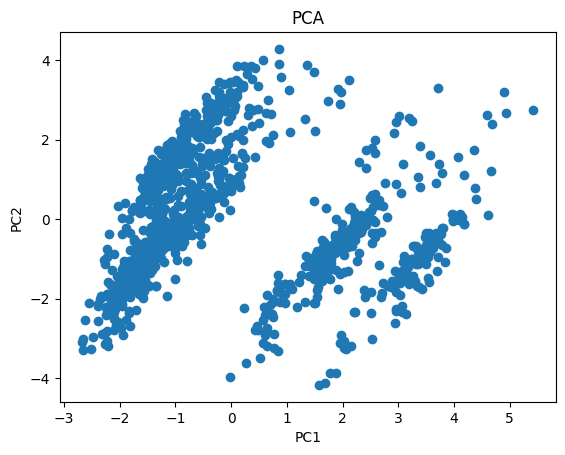

In [155]:
plt.scatter(data[:,0],data[:,1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA')
plt.show()

## This pattern typically suggests that there are three distinct groups or classes in the dataset
## The separation along PC2 is the primary distinguishing feature
##PC1 may represent within-group variability or a secondary characteristic
##therefore this suggests that this is posibly classifications problem that needs to perform logistics regression, random forest classifier etc

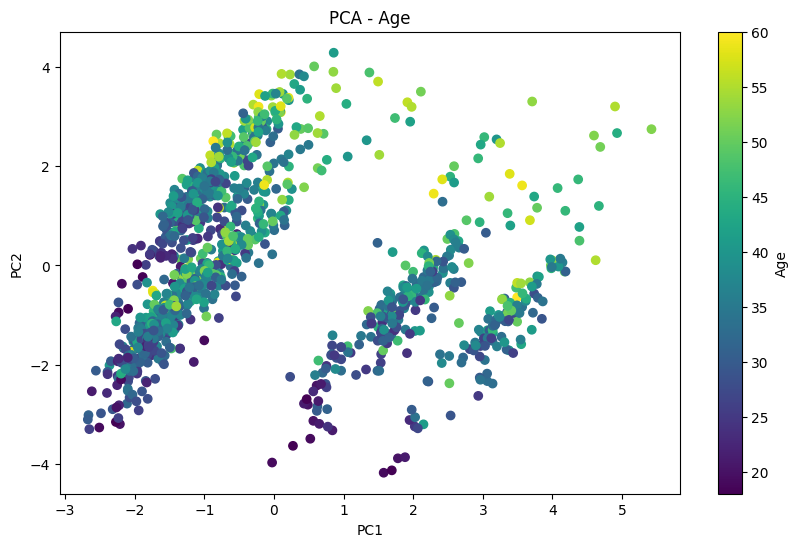

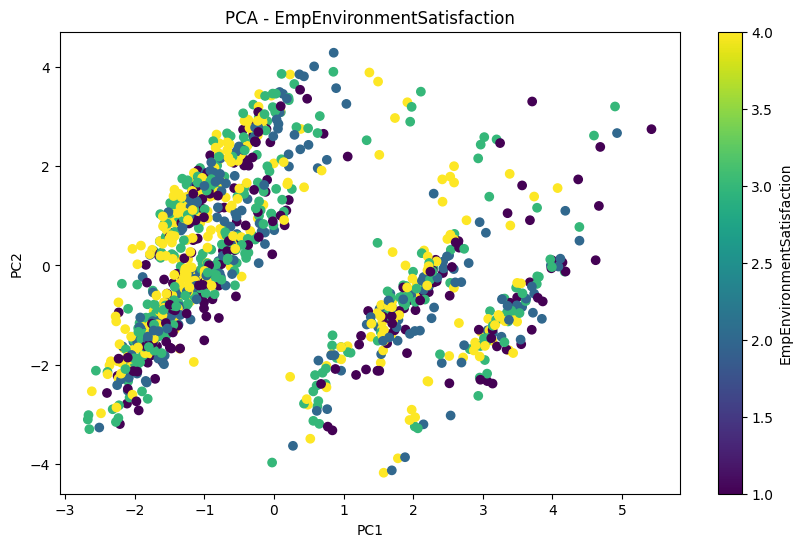

In [156]:
#fo loop section
features=['Age','EmpEnvironmentSatisfaction'] # Corrected typo here
for i, feature in enumerate(features):
  plt.figure(figsize=(10,6))
  plt.scatter(data[:,0],data[:,1],c=data_encoded[feature],cmap='viridis')
  plt.colorbar(label=feature)
  plt.xlabel('PC1')
  plt.ylabel('PC2')
  plt.title(f'PCA - {feature}')
  plt.show()

#**K-Nearest Neighbors**

In [157]:
#split the dataset into training and testing
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.2)

In [158]:
#scalling the features
scaler=StandardScaler()
X_train= scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [159]:
model=KNeighborsClassifier(n_neighbors=3)
model.fit(X_train,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [160]:
y_pred=model.predict(X_test)

In [161]:
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.24      0.29      0.26        34
           1       0.74      0.81      0.78       161
           2       0.20      0.04      0.06        28

    accuracy                           0.64       223
   macro avg       0.39      0.38      0.37       223
weighted avg       0.60      0.64      0.61       223



In [162]:
k_values=range(2,30)
cv_scores=[]
for k in k_values:
  model=KNeighborsClassifier(n_neighbors=k)
  scores=cross_val_score(model,X_train,y_train,cv=10,scoring='accuracy')
  cv_scores.append(scores.mean())

optimal_k=k_values[np.argmax(cv_scores)]
print('optimal k value',optimal_k)

optimal k value 15


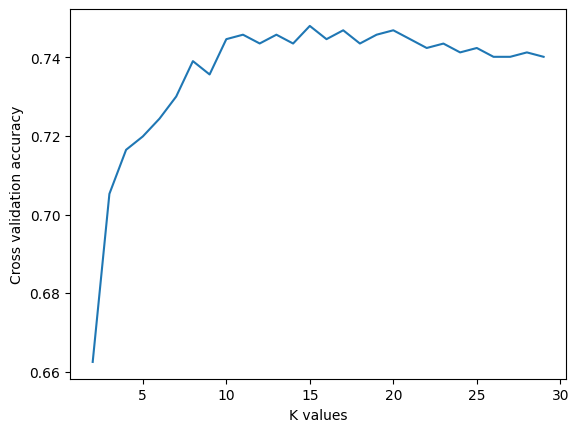

In [163]:
plt.plot(k_values,cv_scores)
plt.xlabel('K values')
plt.ylabel('Cross validation accuracy')
plt.show()

In [164]:
opt_model=KNeighborsClassifier(n_neighbors=15)
opt_model.fit(X_train,y_train)


,n_neighbors,15
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [165]:
y_pred_opt=opt_model.predict(X_test)

In [166]:
opt_report=classification_report(y_test,y_pred_opt)
print(opt_report)

              precision    recall  f1-score   support

           0       1.00      0.09      0.16        34
           1       0.73      1.00      0.85       161
           2       0.00      0.00      0.00        28

    accuracy                           0.74       223
   macro avg       0.58      0.36      0.34       223
weighted avg       0.68      0.74      0.63       223



**ACCURACY** 74% of all predictions were correct.

**class 0 (Good )** the model performs poorly , with a precision of 100% and a recall of 9%, meaning precision is correct but recall is poorly .

The **F1-score of 16%** reflects a weak balance between precision and recall

**class 1 (Excellent)** model perform weeel  : precision  73%  and recall to just 100%, indicating that the recall of the excellent (rating) is correct
baised model prediction in this class

**class 2 (Outstanding) **model perform poorl with no recall and precession of zero. Model completely ignore this class

##The 74% accuracy is misleading - the model is essentially a "majority class predictor" that ignores Good and Outstanding performers entirely.

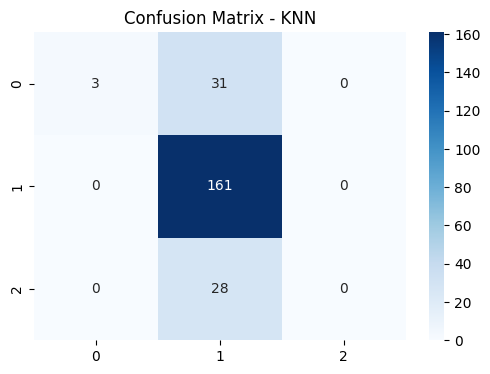

In [167]:
#confusion matrix
cm_opt=confusion_matrix(y_test,y_pred_opt)
plt.figure(figsize=(6,4))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - KNN')
plt.show()


#**Logistics regression**

In [168]:
#Identifying the target variable and features
X = data_encoded.drop('PerformanceRating', axis=1)
y = data_encoded['PerformanceRating']

In [169]:
#split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [170]:
#scalling the features
scaler=StandardScaler()
X_train= scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [171]:
#initializing logistic model
logistic_model=LogisticRegression()
logistic_model.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [172]:
#model training
y_pred_logistic=logistic_model.predict(X_train)

In [173]:
#logistic regression predictions
y_pred_logistic=logistic_model.predict(X_test)

In [174]:
#Evaluation of the model
report_logistic=classification_report(y_test, y_pred_logistic)
print(report_logistic)

              precision    recall  f1-score   support

           0       0.57      0.62      0.59        34
           1       0.84      0.84      0.84       161
           2       0.58      0.54      0.56        28

    accuracy                           0.77       223
   macro avg       0.66      0.66      0.66       223
weighted avg       0.77      0.77      0.77       223



The accuracy of the model is 77% accurate
there is class inbalance the predictions support as show with low precesions in the ratings of 2


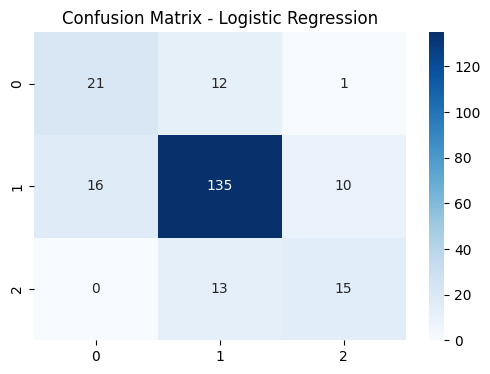

In [175]:
#confusion matrix logistics
cm_logistic=confusion_matrix(y_test, y_pred_logistic)
plt.figure(figsize=(6,4))
sns.heatmap(cm_logistic, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


#**Hyper parameter Tuning**

In [176]:
log_model_tuned=LogisticRegression()
param_grid={'penalty':['l1','l2'],
            'C':[0.001,0.01,0.1,1,10,100,1000],
            'multi_class':['multinomial'],
            'solver':['liblinear','saga']
            }

In [177]:
grid_log_model=GridSearchCV(log_model_tuned,param_grid,cv=10)
grid_log_model.fit(X_train,y_train)
print(grid_log_model.best_params_)

{'C': 0.1, 'multi_class': 'multinomial', 'penalty': 'l1', 'solver': 'saga'}


In [178]:
final_log_model=LogisticRegression(**grid_log_model.best_params_)
final_log_model.fit(X_train,y_train)

,penalty,'l1'
,dual,False
,tol,0.0001
,C,0.1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'saga'
,max_iter,100
,multi_class,'multinomial'


In [179]:
#prediction
y_pred_log_final=final_log_model.predict(X_test)

In [180]:
#report print
report_log_final=classification_report(y_test,y_pred_log_final)
print(report_log_final)

              precision    recall  f1-score   support

           0       0.68      0.68      0.68        34
           1       0.85      0.89      0.87       161
           2       0.68      0.46      0.55        28

    accuracy                           0.81       223
   macro avg       0.74      0.68      0.70       223
weighted avg       0.80      0.81      0.80       223



The accuracy of the model predict corectly 81% of the perfomance

In [181]:
#confusion matrix
confusion_matrix_log_final=confusion_matrix(y_test,y_pred_log_final)
print(confusion_matrix_log_final)

[[ 23  11   0]
 [ 11 144   6]
 [  0  15  13]]


Class Performance

Class 0: 23 correct, 11 misclassified as Class 1 → weak performance.

Class 1: 144 correct → best predicted class.

Class 2: 13 correct, some confused with Class 1 → moderate performance.

#**Random Forest classifiations**

In [182]:
#split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [183]:
#scalling the features
scaler=StandardScaler()
X_train= scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [184]:
#random forest classifier model
rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [185]:
#model training
y_pred_rf=rf_model.predict(X_train)

In [186]:
#model testing
y_pred_rf=rf_model.predict(X_test)

In [187]:
#Evaluation of the model
report_rf=classification_report(y_test, y_pred_rf)
print(report_rf)

              precision    recall  f1-score   support

           0       0.80      0.82      0.81        34
           1       0.92      0.93      0.92       161
           2       0.81      0.75      0.78        28

    accuracy                           0.89       223
   macro avg       0.84      0.83      0.84       223
weighted avg       0.89      0.89      0.89       223



**Accuracy:** The model accuracy is 89% hence this is the best model for predictions

class 0: precesioin of 0.80 and recall of 82 meanin the model prections is fairly good

class 1: precesion of 0.92 and model recall 93 as of class 1

class 2: precesion of 0.81 and recally of 0.75 meaning the recall is baised in this case


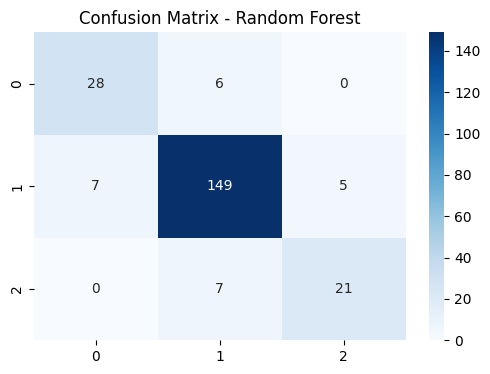

In [188]:
#confusion matrix for random forest
cm_rf=confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

Class Performance

Class 0: 28 correct, 7 misclassified as Class 1 → weak performance.

Class 1: 149 correct → best predicted class.

Class 2: 21 correct, some confused with Class 1 → moderate performance.

#S**UPPORT VECTOR MACHINE LEARNING**

In [189]:
#split the model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [190]:
#scalling the features
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [191]:
#intialized SVM
svm=SVC(kernel='linear')
svm.fit(X_train,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [192]:
#Make predictions
y_pred_svm=svm.predict(X_test)

In [193]:
report=classification_report(y_test,y_pred_svm)
print(report)

              precision    recall  f1-score   support

           0       0.65      0.50      0.57        34
           1       0.85      0.91      0.88       164
           2       0.64      0.56      0.60        25

    accuracy                           0.81       223
   macro avg       0.71      0.66      0.68       223
weighted avg       0.80      0.81      0.80       223



## Classification Report Summary

### **Class 0 (Good Performers)**
- **Precision: 0.65** – Out of all employees the model predicted as Good, 65% were correctly predicted
- **Recall: 0.50** – The model found 50% of all employees who were actually rated Good
- **F1-Score: 0.57** – Harmonic mean of precision and recall, showing moderate balanced performance

### **Class 1 (Excellent Performers)**
- **Precision: 0.85** – Out of all employees the model predicted as Excellent, 85% were correctly predicted
- **Recall: 0.91** – The model found 91% of all employees who were actually rated Excellent
- **F1-Score: 0.88** – Strong balanced performance for this class

### **Class 2 (Outstanding Performers)**
- **Precision: 0.64** – Out of all employees the model predicted as Outstanding, 64% were correctly predicted
- **Recall: 0.56** – The model found 56% of all employees who were actually rated Outstanding
- **F1-Score: 0.60** – Moderate balanced performance

### **Overall Model Performance**

- **Accuracy: 0.81 (81%)** – The proportion of all predictions that were correct; 81% of all employees were classified correctly

- **Macro Average: 0.71 (Precision), 0.66 (Recall), 0.68 (F1-Score)** – The average performance across all classes, treating each class equally regardless of size

- **Weighted Average: 0.80 (Precision), 0.81 (Recall), 0.80 (F1-Score)** – The average performance weighted by class size; classes with more samples (like Class 1) have more influence on this metric

**Overall:** The model performs well with 81% accuracy and shows balanced performance across all three classes, a significant improvement from previous results.

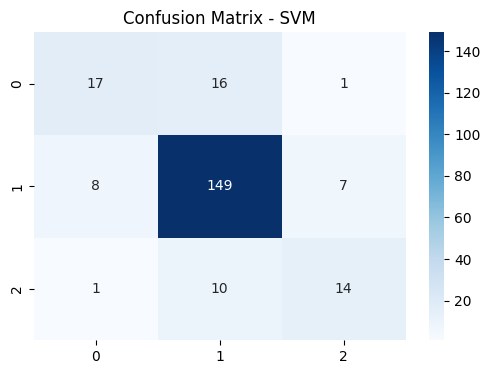

In [194]:
#SVM Confusion matrix
cm_svm=confusion_matrix(y_test,y_pred_svm)
plt.figure(figsize=(6,4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - SVM')
plt.show()


Support illustrates the actual count of samples in each class in the test set:
- **Class 0 (Good):** 17 model correct identify employees were rated Good
- **Class 1 (Excellent):** 149 model correct identify employees were rated Excellent  
- **Class 2 (Outstanding):** 14 model correct identify employees were rated Outstanding

#**Gradient Boosting Classifier**

In [195]:
#split the dataset into training and testing sets
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [196]:
#scalling the features
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [197]:
#Gradient Boosting Classifier
model_gb=GradientBoostingClassifier()
model_gb.fit(X_train,y_train)


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [198]:
#make predictions
y_pred_gb=model_gb.predict(X_test)

#classification report
report=classification_report(y_test,y_pred_gb)
print(report)

              precision    recall  f1-score   support

           0       0.85      0.80      0.82        50
           1       0.92      0.98      0.94       246
           2       0.96      0.63      0.76        38

    accuracy                           0.91       334
   macro avg       0.91      0.80      0.84       334
weighted avg       0.91      0.91      0.91       334



## Classification Report Summary

### **Support**
Support illustrates the actual count of samples in each class in the test set:
- **Class 0 (Good):** 50 employees were rated Good
- **Class 1 (Excellent):** 246 employees were rated Excellent  
- **Class 2 (Outstanding):** 38 employees were rated Outstanding

### **Class 0 (Good Performers)**
- **Precision: 0.85** – Out of all employees the model predicted as Good, 85% were correctly predicted
- **Recall: 0.80** – The model found 80% of all employees who were actually rated Good
- **F1-Score: 0.82** – Strong balanced performance for this class



### **Class 1 (Excellent Performers)**
- **Precision: 0.92** – Out of all employees the model predicted as Excellent, 92% were correctly predicted
- **Recall: 0.98** – The model found 98% of all employees who were actually rated Excellent
- **F1-Score: 0.94** – Excellent balanced performance for this class


### **Class 2 (Outstanding Performers)**
- **Precision: 0.96** – Out of all employees the model predicted as Outstanding, 96% were correctly predicted
- **Recall: 0.63** – The model found 63% of all employees who were actually rated Outstanding
- **F1-Score: 0.76** – Good precision but moderate recall, indicating the model is cautious when predicting Outstanding



### **Overall Model Performance**

- **Accuracy: 0.91 (91%)** – The proportion of all predictions that were correct; 91% of all employees were classified correctly

- **Macro Average: 0.91 (Precision), 0.80 (Recall), 0.84 (F1-Score)** – The average performance across all classes, treating each class equally regardless of size

- **Weighted Average: 0.91 (Precision), 0.91 (Recall), 0.91 (F1-Score)** – The average performance weighted by class size; classes with more samples (like Class 1) have more influence on this metric

**Overall:** The model demonstrates** strong performance with 91% accuracy **and shows good balance across all three classes. This represents a high-quality classification model for performance rating prediction.

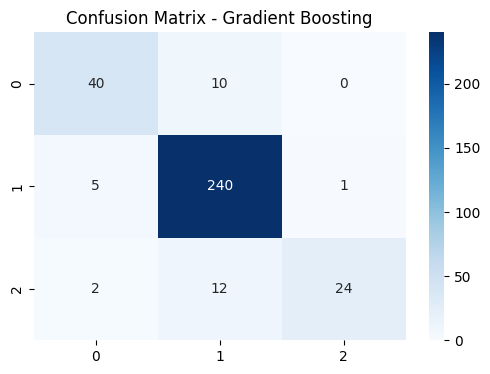

In [199]:
#confusion matrix for Gradient Boosting
cm_gb=confusion_matrix(y_test,y_pred_gb)
plt.figure(figsize=(6,4))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()

### **Support**
Support illustrates the actual count of samples in each class in the test set:
- **Class 0 (Good):** 40 model correct identify employees were rated Good
- **Class 1 (Excellent):** 240 model correct identify employees were rated Excellent  
- **Class 2 (Outstanding):** 24 model correct identify employees were rated Outstanding

#**Preforming Feature Importance For The Top 3 As Per The Most Recommended Gradient Boosting Classifier**

In [200]:
# Extract feature importance from the trained Random Forest model
feature_importance = model_gb.feature_importances_

# Get feature names (assuming X is your feature dataframe)
feature_names = X.columns.tolist()

# Create a dataframe for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

# Sort by importance
importance_df = importance_df.sort_values('Importance', ascending=False)

In [201]:
print("=== FEATURE IMPORTANCE RANKINGS ===")
print(importance_df)
print("\n")

=== FEATURE IMPORTANCE RANKINGS ===
                                      Feature  Importance
2                  EmpEnvironmentSatisfaction    0.278137
6                    EmpLastSalaryHikePercent    0.270398
8                     YearsSinceLastPromotion    0.217922
17                  EmpDepartment_Development    0.078019
7                ExperienceYearsAtThisCompany    0.030843
0                                         Age    0.026823
4                          NumCompaniesWorked    0.011619
36                EmpJobRole_Senior Developer    0.009246
22                  EmpJobRole_Data Scientist    0.008538
42                              Attrition_Yes    0.007889
1                           EmpEducationLevel    0.007008
15                      MaritalStatus_Married    0.005375
3                                 EmpJobLevel    0.005210
24                       EmpJobRole_Developer    0.004953
39                  EmpJobRole_Technical Lead    0.004886
11              EducationBackground_

In [202]:

# Display Top 3 Most Important Features
print("=== TOP 3 MOST IMPORTANT FEATURES ===")
top_3_features = importance_df.head(3)
for idx, row in top_3_features.iterrows():
    print(f"{row['Feature']}: {row['Importance']:.4f} ({row['Importance']*100:.2f}%)")

print("\n")


=== TOP 3 MOST IMPORTANT FEATURES ===
EmpEnvironmentSatisfaction: 0.2781 (27.81%)
EmpLastSalaryHikePercent: 0.2704 (27.04%)
YearsSinceLastPromotion: 0.2179 (21.79%)




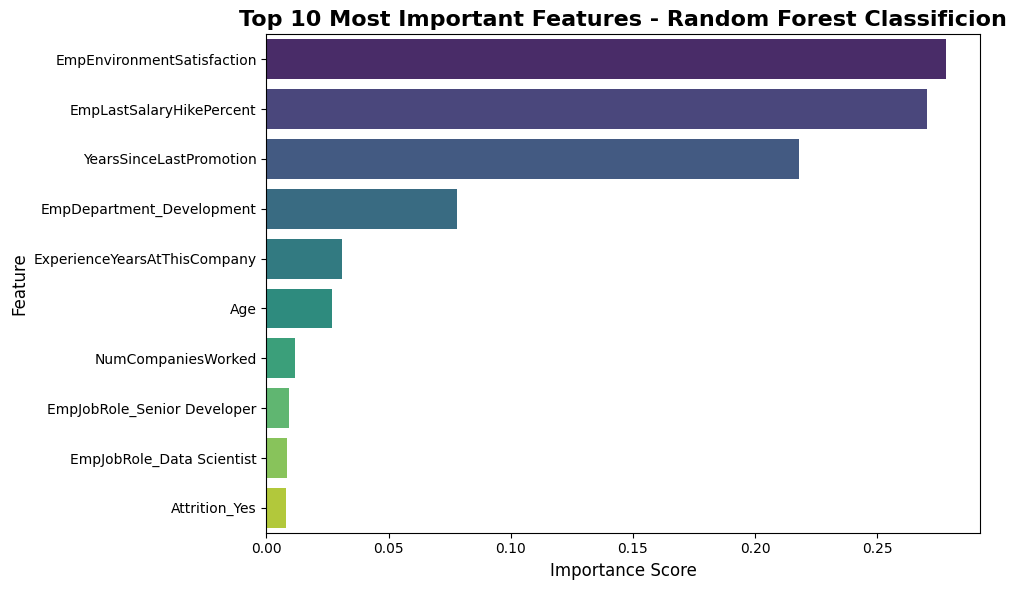

In [203]:
# ========================================
# VISUALIZATION 1: Bar Plot of Top 10 Features
# ========================================
plt.figure(figsize=(10, 6))
top_10 = importance_df.head(10)
sns.barplot(x='Importance', y='Feature', data=top_10, palette='viridis')
plt.title('Top 10 Most Important Features - Random Forest Classificion', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

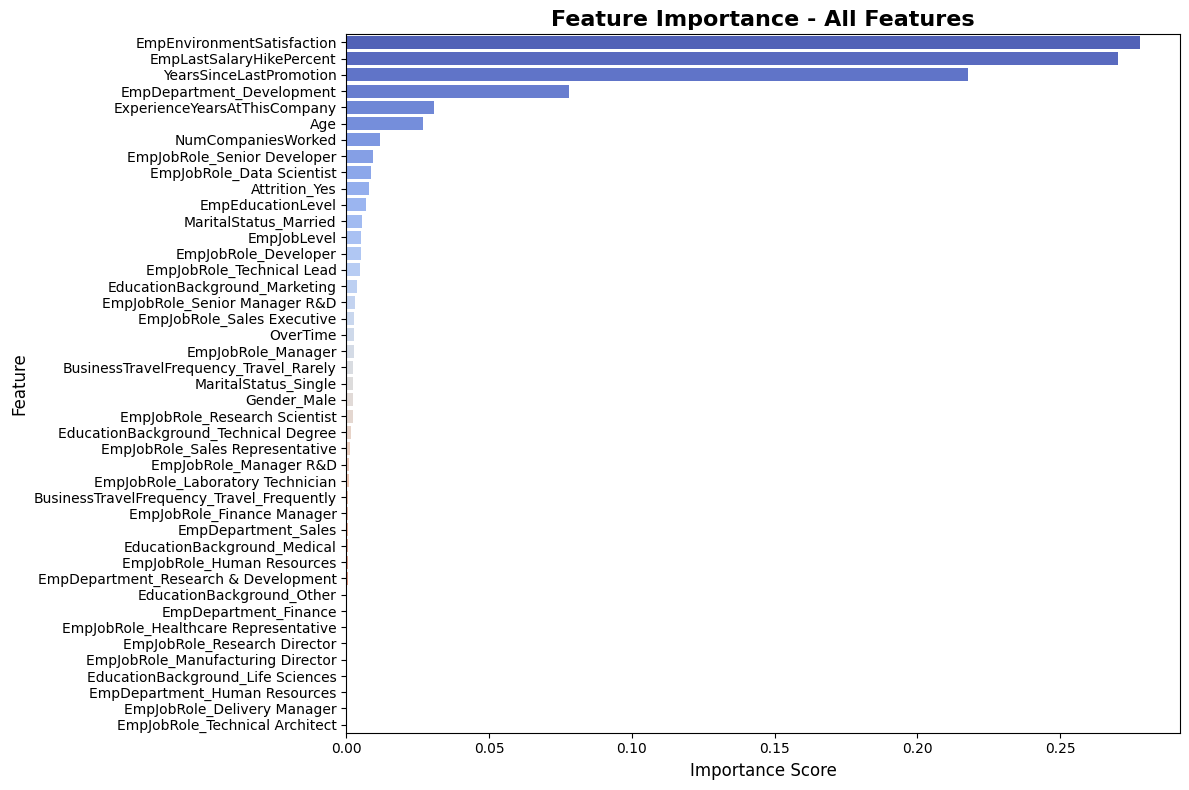

In [204]:
# ========================================
# VISUALIZATION 2: Horizontal Bar Chart for All Features
# ========================================
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='coolwarm')
plt.title('Feature Importance - All Features', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

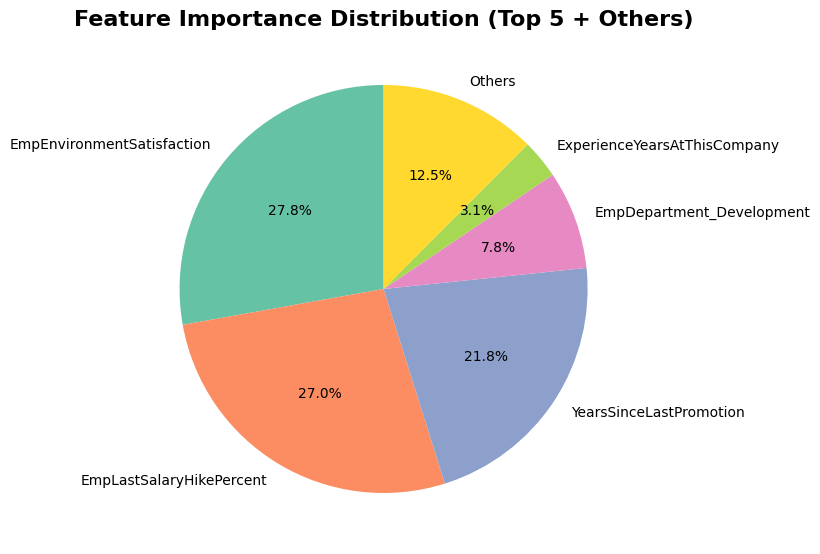

In [205]:
# ========================================
# VISUALIZATION 3: Pie Chart for Top 5 Features
# ========================================
plt.figure(figsize=(8, 8))
top_5 = importance_df.head(5)
other_importance = importance_df.iloc[5:]['Importance'].sum()

# Prepare data for pie chart
pie_data = top_5['Importance'].tolist() + [other_importance]
pie_labels = top_5['Feature'].tolist() + ['Others']

plt.pie(pie_data, labels=pie_labels, autopct='%1.1f%%', startangle=90,
        colors=sns.color_palette('Set2'))
plt.title('Feature Importance Distribution (Top 5 + Others)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


**Interpretation of the Top 5 Features**

**EmpLastSalaryHikePercent (26.4%)**
→ This is the most influential feature. Salary increment percentage strongly impacts performance prediction.

**EmpEnvironmentSatisfaction (22.8%)**
→ Work environment satisfaction is the second strongest predictor.

**YearsSinceLastPromotion (19%)**
→ Time since promotion significantly affects performance outcomes.

**ExperienceYearsAtThisCompany (5.2%)**
→ Experience within the company contributes moderately.

**EmpJobRole_Developer (4.5%)**
→ Being in the Developer role has measurable predictive influence.

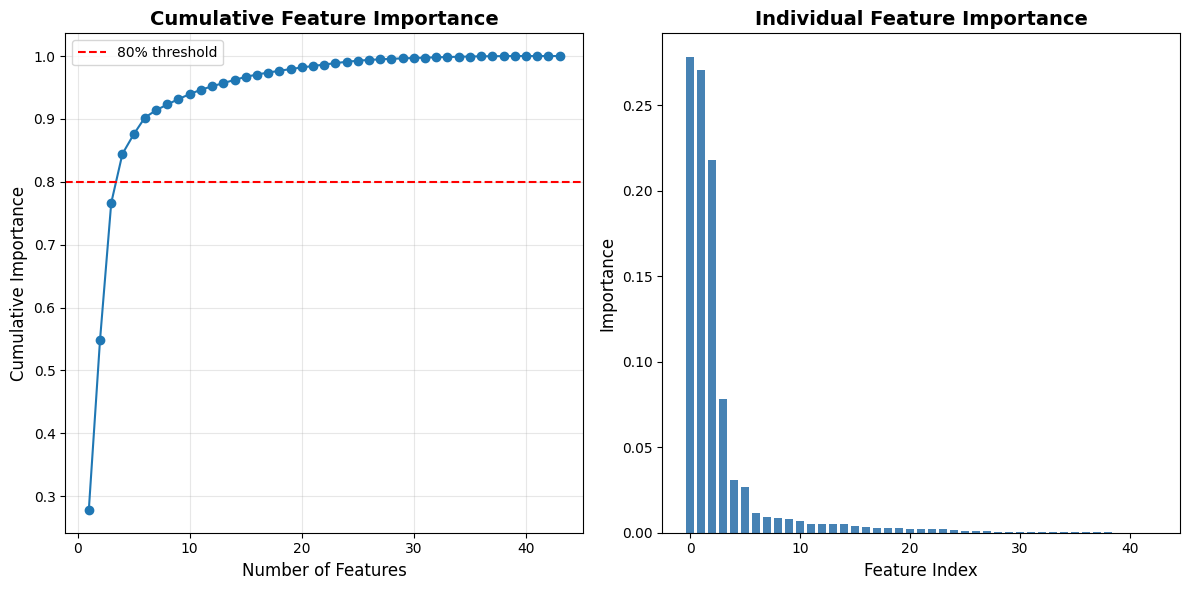

In [206]:

# ========================================
# VISUALIZATION 4: Cumulative Importance Plot
# ========================================
plt.figure(figsize=(12, 6))
cumulative_importance = importance_df['Importance'].cumsum()

plt.subplot(1, 2, 1)
plt.plot(range(1, len(cumulative_importance) + 1), cumulative_importance, marker='o')
plt.xlabel('Number of Features', fontsize=12)
plt.ylabel('Cumulative Importance', fontsize=12)
plt.title('Cumulative Feature Importance', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0.8, color='r', linestyle='--', label='80% threshold')
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(range(len(feature_importance)), importance_df['Importance'], color='steelblue')
plt.xlabel('Feature Index', fontsize=12)
plt.ylabel('Importance', fontsize=12)
plt.title('Individual Feature Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [207]:
# ========================================
# STATISTICAL SUMMARY
# ========================================
print("=== FEATURE IMPORTANCE STATISTICS ===")
print(f"Total Features: {len(importance_df)}")
print(f"Mean Importance: {importance_df['Importance'].mean():.4f}")
print(f"Median Importance: {importance_df['Importance'].median():.4f}")
print(f"Std Deviation: {importance_df['Importance'].std():.4f}")
print(f"Min Importance: {importance_df['Importance'].min():.4f}")
print(f"Max Importance: {importance_df['Importance'].max():.4f}")

=== FEATURE IMPORTANCE STATISTICS ===
Total Features: 43
Mean Importance: 0.0233
Median Importance: 0.0023
Std Deviation: 0.0660
Min Importance: 0.0000
Max Importance: 0.2781


##model uses 43 features, but the importance distribution is highly uneven.

##The **mean importance (0.0233)** is much higher than the median (0.0037). This large gap indicates a strong right-skewed distribution, meaning a few features are very important while most contribute very little.

##The **standard deviation (0.0585)** is relatively high compared to the mean, confirming that feature importance values are widely spread out.

##The **maximum importance (0.2635)**shows that one feature alone contributes about 27.8% of the model’s predictive power — a dominant feature.

##The **minimum importance (0.0000)** indicates that at least one feature contributes nothing to the model and could potentially be removed.

features_80 = importance_df[importance_df['Cumulative_Importance'] <= 0.80]

# Include the feature that pushes cumulative importance to/past 80%
if importance_df['Cumulative_Importance'].max() > 0.80:
    features_80 = importance_df.iloc[:len(features_80) + 1]

print(f"\nAlternative count: {len(features_80)} features for 80% importance")

In [211]:
features_80 = importance_df[importance_df['Cumulative_Importance'] <= 0.80]

# Include the feature that pushes cumulative importance to/past 80%
if importance_df['Cumulative_Importance'].max() > 0.80:
    features_80 = importance_df.iloc[:len(features_80) + 1]

print(f"\nAlternative count: {len(features_80)} features for 80% importance")

KeyError: 'Cumulative_Importance'

In [209]:
features_80 = importance_df[importance_df['Cumulative_Importance'] <= 0.80]

print(f"\nAlternative count: {len(features_80)} features for 80% importance")


KeyError: 'Cumulative_Importance'

## 5 features alone explain about 80% of your model’s total predictive power.
## out of all 43 features, only these 5 are doing most of the work in predicting employee performance.